$ \textbf{Aluna:}$ Alessandra da Silva Dias Malizia   
$ \textbf{Professor:}$ Cristiano Fernandes   
$ \textbf{Data:}$ 9 de Outubro de 2026

$ \textbf{Tese de Mestrado - 2026.1:}$ Modelagem de vazão de rios utilizando a distribuição de Harvey

In [1]:
import numpy as np
import pandas as pd
import datetime as dt
import harvey_gev as harvey

import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from scipy.stats import genextreme, uniform
import seaborn as sns
import statsmodels.api as sm
import importlib
from scipy.special import expit, gamma as gamma_func
# from scipy.constants import EulerGamma

In [2]:
gamma_E = 0.5772156649015329

In [187]:
import inspect
print(inspect.getsource(harvey.composite_score))

def composite_score(y, xi, mu=0, gamma=0, varphi=1, c={}, d={}, I={}):
    """
    Composite score do modelo de Harvey.

    Returns
    -------
    s_dagger : float or np.ndarray
        Composite score s_t^dagger.
    """
    # y = np.asarray(y, dtype=float)
    # xi = np.asarray(xi, dtype=float)
    y, xi, mu, gamma = (
        a.ravel() for a in (y, xi, mu, gamma)
    )
    x = _standardized_residual(y, mu, gamma, varphi)

    s_composite = np.empty_like(x, dtype=float)
    
    # Caso Gumbel
    mask0 = np.abs(xi) < 1e-6
    x0 = x[mask0]
    s0 = varphi * x0
    s0[x0 > 0] = varphi * (1 - np.exp(-x0[x0 > 0]))
    s_composite[mask0] = s0

    # Caso Fréchet
    mask1 = ~mask0

    s_f = np.empty_like(xi[mask1], dtype=float)
    for xi_value in np.unique(xi[mask1]):

        idx = mask1 & (xi == xi_value)
        x_i = x[idx]

        if xi_value not in c: 
            c[xi_value] = _find_c(xi_value) 
        if xi_value not in d: 
            d[xi_value] = _find_d(xi_value)
      

In [190]:
def salvar_resultados(
    result,
    arquivo="Resultados do Modelo.xlsx",
    observacoes=""
):
    # Data e horário da estimação/salvamento
    momento = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

    # Parâmetros estimados, na ordem fixa original
    parametros = dict(
        zip(result.param_names, result.params_original)
    )

    # Linha com informações do ajuste
    nova_linha = {
        "Data e horário": momento,
        **parametros,
        "Log-verossimilhança": -result.fun,
        "Convergiu": result.success,
        "Mensagem": result.message,
        "Método": getattr(result, "method", ""),
        "Modo xi": result.xi_mode,
        "Modo varphi": result.varphi_mode,
        "Observações": observacoes
    }

    df_novo = pd.DataFrame([nova_linha])

    # Se existir, preserva as linhas anteriores
    if os.path.exists(arquivo):
        df_antigo = pd.read_excel(arquivo)

        # Preserva também colunas existentes de execuções anteriores
        df_final = pd.concat(
            [df_antigo, df_novo],
            ignore_index=True,
            sort=False
        )
    else:
        df_final = df_novo

    # Salva o arquivo Excel
    df_final.to_excel(arquivo, index=False)

    print(f"Resultados salvos em: {os.path.abspath(arquivo)}")
    print(f"Data e horário: {momento}")

    return df_final

# Dados BR

- Dados BR: Vazão do Rio Amazonas na estação 14990000 [https://www.snirh.gov.br/hidroweb/serieshistoricas]
- Dados Harvey: daily river Exe flow e level na base de Thorverton [https://environment.data.gov.uk/hydrology/station/3c4d4f78-2d0e-474a-b884-65a9daca18fb]  
  Grid Reference: SS9360201602
  River Name: River Exe  
  Catchment Area: 600.9 km²  
  Station Reference (Telemetry): 45118  
  Station ID (WISKI): SS90F011  
  API: https://environment.data.gov.uk/hydrology/doc/reference

In [161]:
path = r"C:\Users\aless\Documents\Mestrado\PUC\Tese\Dados\14990000_Cotas.csv"
data = pd.read_csv(path, skiprows=15, encoding='latin-1', sep=';') #, decimal=','

data = data[['Data', 'Maxima','Minima','Media']]
data['Data'] = pd.to_datetime(data['Data'], format='%d/%m/%Y')
data = data.set_index('Data').dropna(how='all')

data = data.resample('ME').mean()
data.at['2014-08-31','Media'] = 2546
data.at['2014-08-31','Maxima'] = 2906

series = data[['Maxima']].dropna()

print(data.shape)
data.head(3)

(1347, 3)


,Maxima,Minima,Media
Data,,,
1902-09-30,2219.0,NaN,NaN
1902-10-31,1970.0,1777.0,1818.0
1902-11-30,1776.5,1680.5,1716.5


In [4]:
# metadados
pd.set_option('display.max_colwidth', None)
pd.DataFrame(index=['Metadados'], data={
    'Fonte':'''Base de dados de vazão do Rio Amazonas da Agência Nacional de Águas (ANA)''', 
    'Unidade':'centímetros (cm)',
    'Período da série': '{} a {}'.format(series.index.min().strftime('%d/%m/%Y'), series.index.max().strftime('%d/%m/%Y')),
    'Observações': '{} meses'.format(series.shape[0])
}).T

,Metadados
Fonte,Base de dados de vazão do Rio Amazonas da Agência Nacional de Águas (ANA)
Unidade,centímetros (cm)
Período da série,30/09/1902 a 30/11/2014
Observações,1347 meses


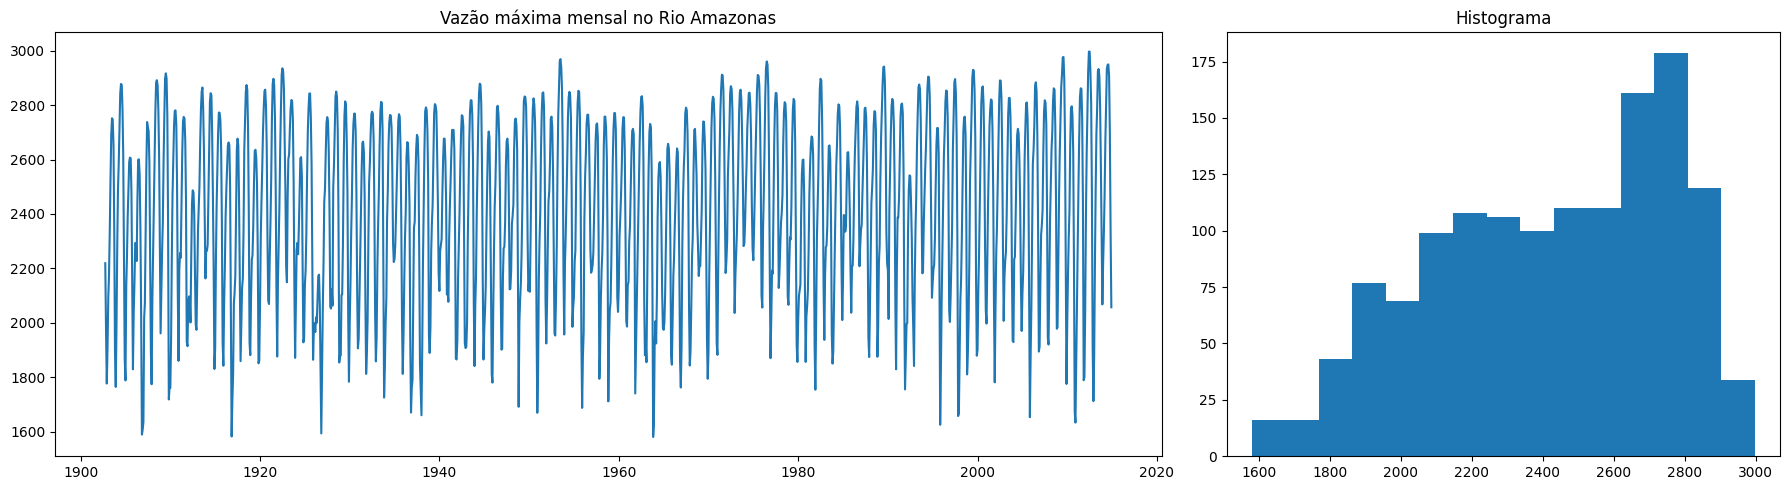

In [96]:
fig, ax = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={'width_ratios': [2, 1]})

ax[0].plot(series)
ax[0].set_title('Vazão máxima mensal no Rio Amazonas')

ax[1].hist(series, bins=15)
ax[1].set_title('Histograma')

plt.tight_layout()
plt.show()

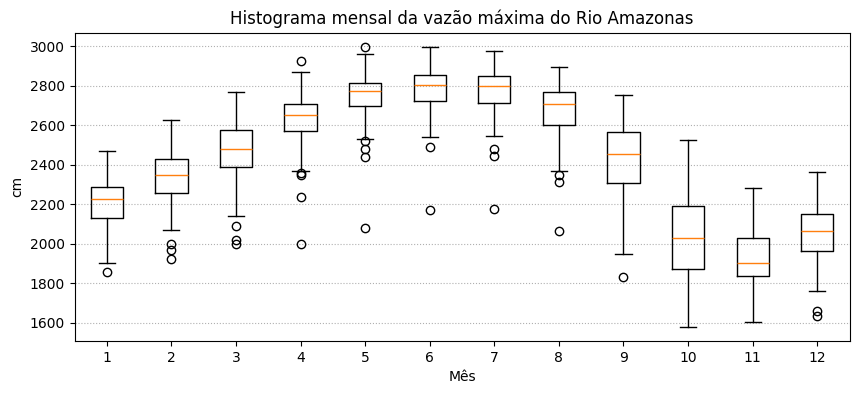

In [5]:
fig, ax = plt.subplots(figsize=(10,4))
plot_data = (series
    .pivot_table(columns=series.index.month, index=series.index.year, values='Maxima')
    .dropna()
)
ax.boxplot(plot_data)
ax.set_ylabel('cm')
ax.set_xlabel('Mês')
ax.grid(axis='y', linestyle=':')
ax.set_title('Histograma mensal da vazão máxima do Rio Amazonas')
plt.show()

## Modelagem

\begin{align}
y_t &= \mu_{t|t-1} + \gamma_t+\varphi\varepsilon_t, \qquad \text{com} \quad
\varepsilon_t \sim
\operatorname{GEV}(0,1,\xi_t) \quad \text{e} \quad
\varphi > 0 \\
\mu_{t+1|t} &= \mu(1-\phi) +\phi\mu_{t|t-1} +\kappa s_t \\
\gamma_t &=
\sum_{j=1}^{6}
\left(
\alpha_j
\cos\left(\frac{2\pi jt}{12}\right)
+
\beta_j
\sin\left(\frac{2\pi jt}{12}\right)
\right)
\end{align}

In [225]:
importlib.reload(harvey)

<module 'harvey_gev' from 'C:\\Users\\aless\\Desktop\\Codes\\masters\\Tese\\harvey_gev.py'>

In [162]:
y = series['Maxima']
mu_init, alpha_init, beta_init = harvey.initial_seasonal_coefficients(y)

t = np.arange(1, len(series) + 1)
gamma_init = harvey.seasonal_component(t, alpha_init, beta_init)
residuos_init = y.to_numpy(dtype=float) - mu_init - gamma_init
varphi_init = np.std(residuos_init)

print(f"mu inicial: {mu_init:.2f}")
print(f"varphi inicial: {varphi_init:.2f}")

# temporada de cheia de março a agosto
dummy = series.index.month.isin([3,4,5,6,7,8]).astype(int)

mu inicial: 2422.10
varphi inicial: 147.10


In [165]:
bounds = [
    (None, None),   # mu0
    (1e-8, None),   # varphi > 0
    (-0.999, 0.999),   # -1 < phi < 1
    (1e-8, None),   # kappa > 0
    (1e-8, 1),     # 0 < xi_seca < 1/2
    # (1e-8, 1)     # 0 < xi_cheia < 1/2
]
bounds += [(None, None)] * 11  # alpha e beta

init_params = [
    2422,     # mu
    147,     # varphi
    0.55,   # phi
    0.3,    # kappa
    0.1,    # xi seca
    # 0.2, # xi cheia
    *alpha_init,
    *beta_init
]
start = dt.datetime.now()
print(start)
result = harvey.fit(y, dummy, init_params, bounds=None, xi_mode="constant")
end = dt.datetime.now()
print(f"Tempo de execução: {(end-start).seconds//60:02d}:{(end-start).seconds%60:02d}")

mu_hat, varphi_hat, phi_hat, kappa_hat, xi_seca_hat, xi_cheia_hat = result.params_original[:6]
alpha_hat = result.params_original[6:12]
beta_hat = result.params_original[12:17]

2026-10-21 09:54:19.197492
Tempo de execução: 18:43


In [166]:
print("Convergiu:", result.success)
print("Mensagem:", result.message)

print("\nEstimativas:")
print(f"mu: {result.params_original[0]:.3f}")
print(f"varphi: {result.params_original[1]:.3f}")
print(f"phi: {result.params_original[2]}")
print(f"kappa: {result.params_original[3]}")
print(f"xi seca: {result.params_original[4]}")
print(f"xi cheia: {result.params_original[5]}")

print("\nLog-likelihood =", -result.fun)

Convergiu: True
Mensagem: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH

Estimativas:
mu: 2307.366
varphi: 87.968
phi: 0.7636967767906566
kappa: 1.6214735725476104
xi seca: 1e-08
xi cheia: 1e-08

Log-likelihood = -7984.065158953967


In [83]:
print("Convergiu:", result.success)
print("Mensagem:", result.message)

print("\nEstimativas:")
print(f"mu: {result.params_original[0]:.3f}")
print(f"varphi: {result.params_original[1]:.3f}")
print(f"phi: {result.params_original[2]}")
print(f"kappa: {result.params_original[3]}")
print(f"xi seca: {result.params_original[4]}")
print(f"xi cheia: {result.params_original[5]}")

print("\nLog-likelihood =", -result.fun)

Convergiu: True
Mensagem: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH

Estimativas:
mu: 2035.073
varphi: 104.508
phi: 0.6613157550347734
kappa: 2.8937243443352294
xi seca: 1e-08
xi cheia: 1e-08

Log-likelihood = -8218.161885560336


In [167]:
result

         message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
         success: True
          status: 0
             fun: 7984.065158953967
               x: [ 2.307e+03  8.797e+01 ...  1.799e+01  1.946e+00]
             nit: 425
             jac: [-1.010e-02  1.401e-02 ...  1.737e-02 -2.237e-02]
            nfev: 8296
            njev: 488
        hess_inv: <16x16 LbfgsInvHessProduct with dtype=float64>
 params_original: [ 2.307e+03  8.797e+01 ...  1.799e+01  1.946e+00]

In [82]:
result

         message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
         success: True
          status: 0
             fun: 8218.161885560336
               x: [ 2.035e+03  1.045e+02 ...  7.985e+00  4.237e+00]
             nit: 75
             jac: [ 5.695e-01  1.572e+00 ... -1.161e-01  2.043e+00]
            nfev: 1938
            njev: 114
        hess_inv: <16x16 LbfgsInvHessProduct with dtype=float64>
 params_original: [ 2.035e+03  1.045e+02 ...  7.985e+00  4.237e+00]

## Avaliação

In [168]:
mu_filtered, gamma_t, x, s, xi_t = harvey.filter(
    y, mu_hat, varphi_hat, phi_hat, kappa_hat, xi_seca_hat, xi_cheia_hat, dummy, alpha_hat, beta_hat
)
eta_t = mu_filtered + gamma_t
mean_cond = harvey.conditional_mean(mu_filtered, varphi_hat, xi_t, gamma_t)

pit = harvey.cdf(y, mu_filtered, varphi_hat, xi_t, gamma_t)

In [169]:
# regiões modificadas do score
mask_gumbel = (np.abs(xi_t) < 1e-6) & (x < 0)
mask_lower = np.zeros(len(x), dtype=bool)
mask_upper = np.zeros(len(x), dtype=bool)

c, d = {}, {}
c_t = np.full(len(x), np.nan)
d_t = np.full(len(x), np.nan)

for xi_value in np.unique(xi_t):
    if xi_value > 1e-6:
        c[xi_value] = harvey._find_c(xi_value)
        d[xi_value] = harvey._find_d(xi_value)

for i in range(len(x)):
    if xi_t[i] > 1e-6:
        c_t[i], d_t[i] = c[xi_value], d[xi_value]
        mask_lower[i] = x[i] <= c_t[i]
        mask_upper[i] = x[i] > d_t[i]

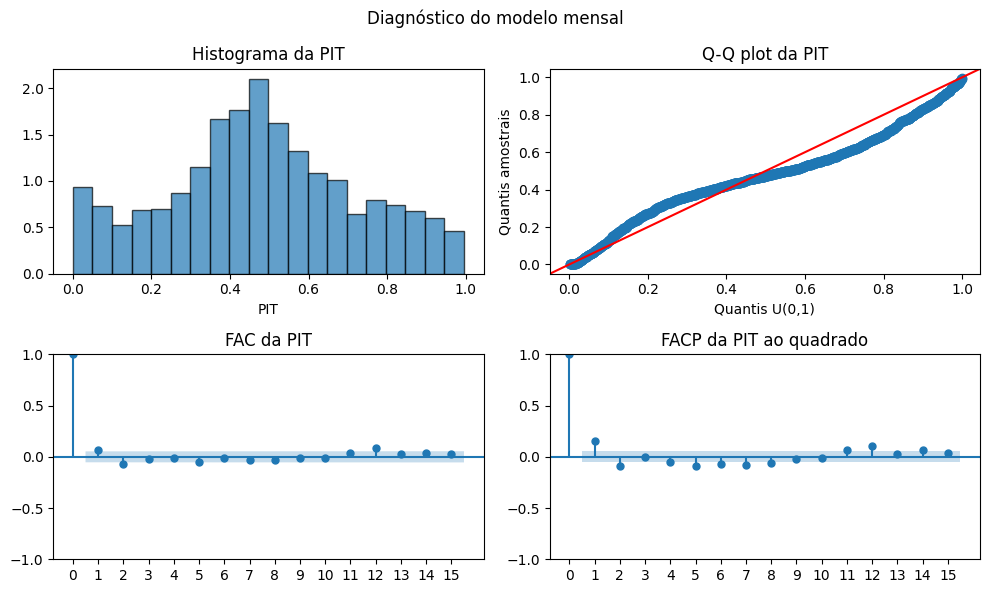

In [170]:
# pit
fig, ax = plt.subplots(2, 2, figsize=(10, 6))

# linha 1
ax[0,0].hist(pit, bins=20, density=True, edgecolor='black', alpha=0.7)
ax[0,0].set_title('Histograma da PIT')
ax[0,0].set_xlabel('PIT')

ax[0,1].set_title('Q-Q plot da PIT')
sm.qqplot(pit, dist=uniform, line='45', ax=ax[0,1], loc=0, scale=1)
ax[0,1].set_xlabel('Quantis U(0,1)')
ax[0,1].set_ylabel('Quantis amostrais')

# linha 2
lags = 15

plot_acf(pit, lags=lags, ax=ax[1,0], title='FAC da PIT')
ax[1,0].set_xticks(np.arange(lags+1))
ax[1,0].set_xticklabels(np.arange(lags+1))

plot_pacf(pit**2, lags=lags, ax=ax[1,1], title='FACP da PIT ao quadrado')
ax[1,1].set_xticks(np.arange(lags+1))
ax[1,1].set_xticklabels(np.arange(lags+1))

fig.suptitle('Diagnóstico do modelo mensal')
fig.tight_layout()
plt.show()

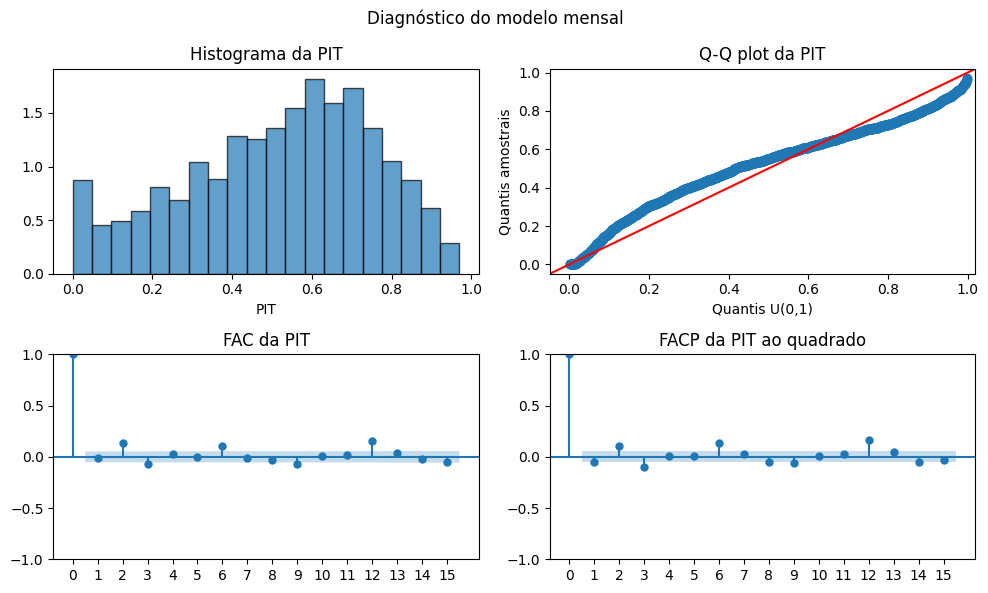

In [85]:
# pit
fig, ax = plt.subplots(2, 2, figsize=(10, 6))

# linha 1
ax[0,0].hist(pit, bins=20, density=True, edgecolor='black', alpha=0.7)
ax[0,0].set_title('Histograma da PIT')
ax[0,0].set_xlabel('PIT')

ax[0,1].set_title('Q-Q plot da PIT')
sm.qqplot(pit, dist=uniform, line='45', ax=ax[0,1], loc=0, scale=1)
ax[0,1].set_xlabel('Quantis U(0,1)')
ax[0,1].set_ylabel('Quantis amostrais')

# linha 2
lags = 15

plot_acf(pit, lags=lags, ax=ax[1,0], title='FAC da PIT')
ax[1,0].set_xticks(np.arange(lags+1))
ax[1,0].set_xticklabels(np.arange(lags+1))

plot_pacf(pit**2, lags=lags, ax=ax[1,1], title='FACP da PIT ao quadrado')
ax[1,1].set_xticks(np.arange(lags+1))
ax[1,1].set_xticklabels(np.arange(lags+1))

fig.suptitle('Diagnóstico do modelo mensal')
fig.tight_layout()
plt.show()

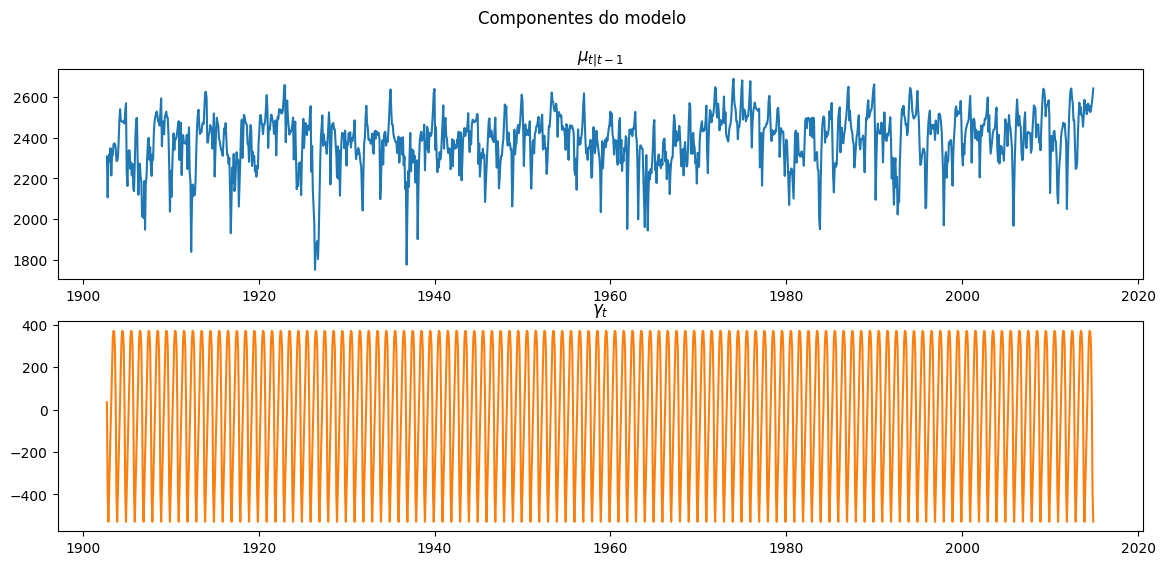

In [171]:
fig, ax = plt.subplots(2, 1, figsize=(14, 6))

ax[0].plot(series.index, mu_filtered, label=r"$\mu_{t|t-1}$")
ax[0].set_title(r"$\mu_{t|t-1}$")

ax[1].plot(series.index, gamma_t, label=r"$\gamma_t$", color='C1')
ax[1].set_title(r"$\gamma_t$")

fig.suptitle("Componentes do modelo")
# plt.legend()
plt.show()

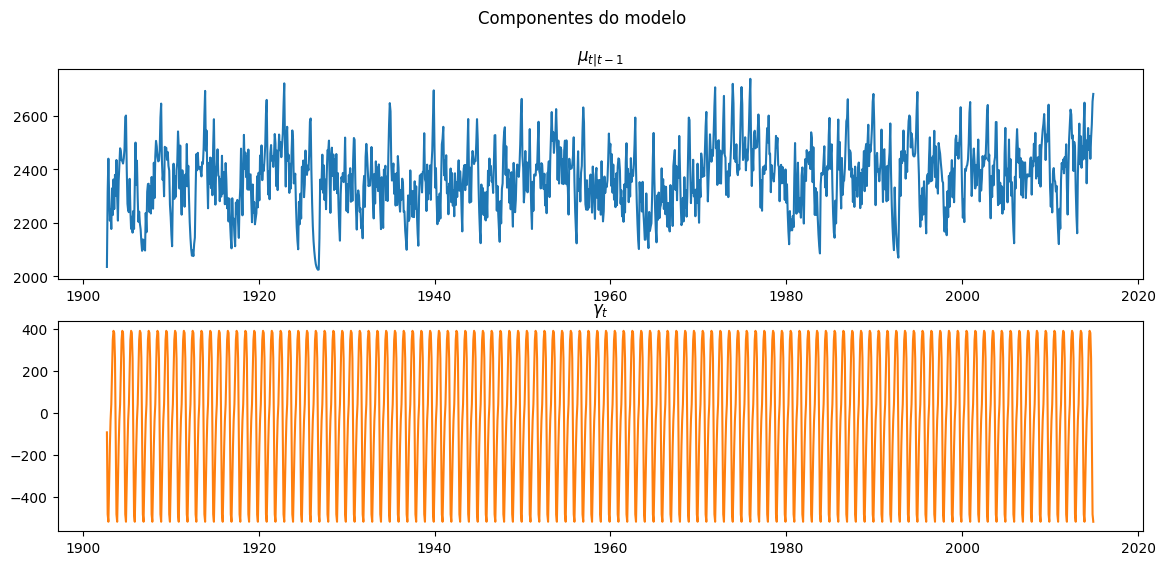

In [86]:
fig, ax = plt.subplots(2, 1, figsize=(14, 6))

ax[0].plot(series.index, mu_filtered, label=r"$\mu_{t|t-1}$")
ax[0].set_title(r"$\mu_{t|t-1}$")

ax[1].plot(series.index, gamma_t, label=r"$\gamma_t$", color='C1')
ax[1].set_title(r"$\gamma_t$")

fig.suptitle("Componentes do modelo")
# plt.legend()
plt.show()

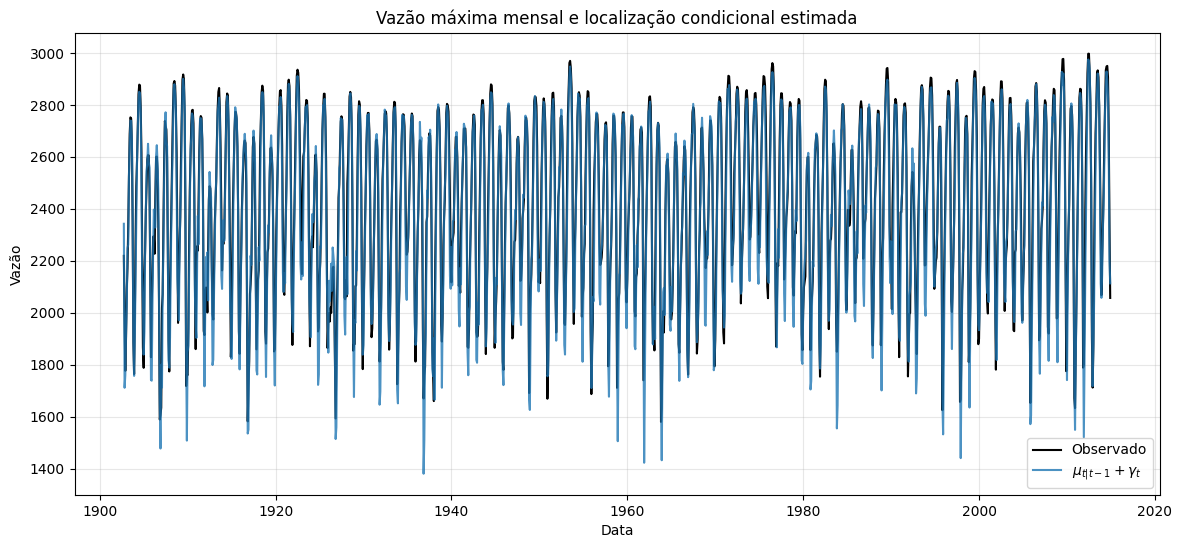

In [172]:
plt.figure(figsize=(14, 6))

plt.plot(series.index, series, label="Observado", color='black')
plt.plot(series.index, eta_t, label=r"$\mu_{t|t-1} + \gamma_t$", alpha=0.8)
# plt.plot(series.index, mean_cond, label=r"$E[y_t|\mathcal{F}_{t-1}]$")

plt.xlabel("Data")
plt.ylabel("Vazão")
plt.title("Vazão máxima mensal e localização condicional estimada")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

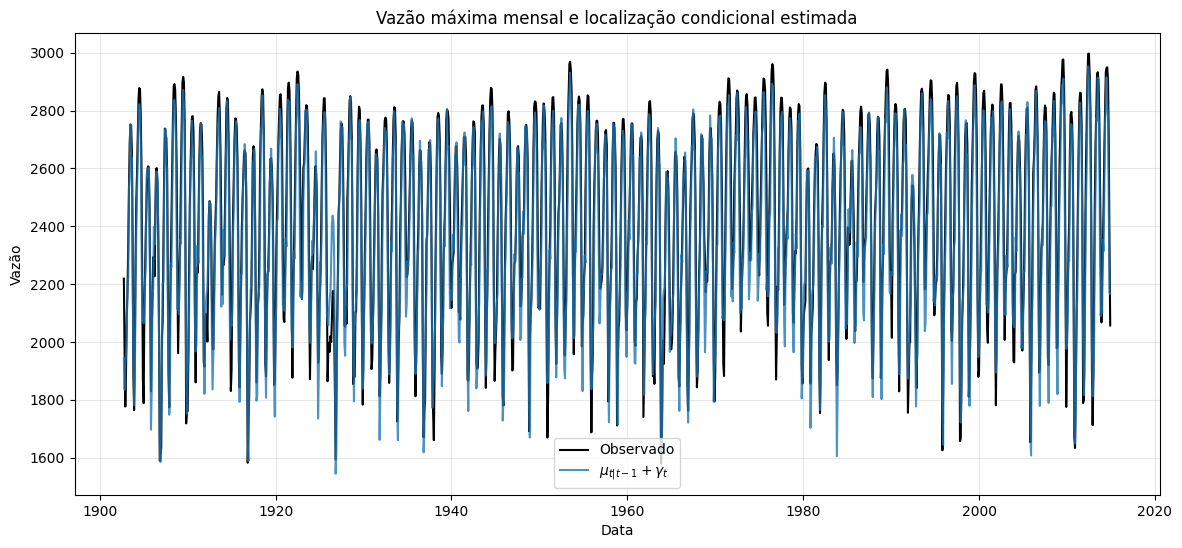

In [91]:
plt.figure(figsize=(14, 6))

plt.plot(series.index, series, label="Observado", color='black')
plt.plot(series.index, eta_t, label=r"$\mu_{t|t-1} + \gamma_t$", alpha=0.8)
# plt.plot(series.index, mean_cond, label=r"$E[y_t|\mathcal{F}_{t-1}]$")

plt.xlabel("Data")
plt.ylabel("Vazão")
plt.title("Vazão máxima mensal e localização condicional estimada")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

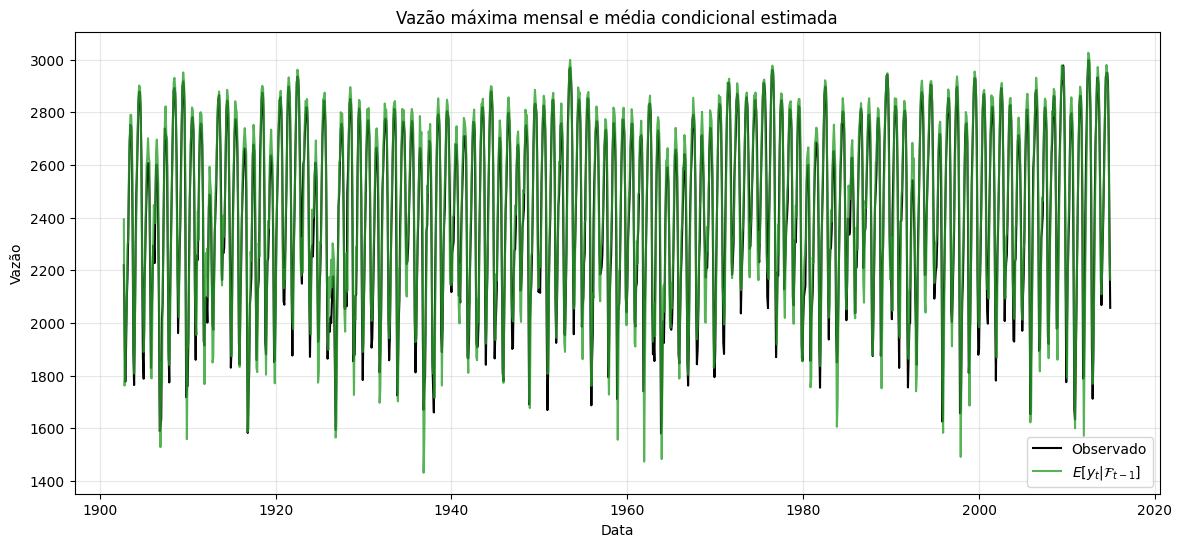

In [173]:
plt.figure(figsize=(14, 6))

plt.plot(series.index, series, label="Observado", color='black')
# plt.plot(series.index, eta_t, label=r"$\mu_{t|t-1} + \gamma_t$")
plt.plot(series.index, mean_cond, label=r"$E[y_t|\mathcal{F}_{t-1}]$", color='C2', alpha=0.8)

plt.xlabel("Data")
plt.ylabel("Vazão")
plt.title("Vazão máxima mensal e média condicional estimada")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

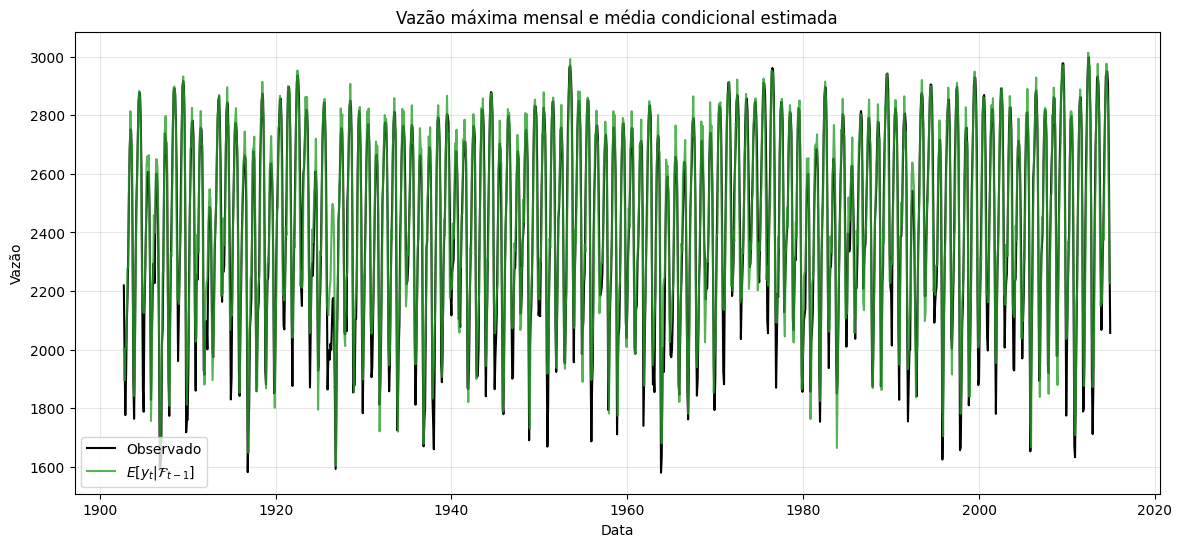

In [94]:
plt.figure(figsize=(14, 6))

plt.plot(series.index, series, label="Observado", color='black')
# plt.plot(series.index, eta_t, label=r"$\mu_{t|t-1} + \gamma_t$")
plt.plot(series.index, mean_cond, label=r"$E[y_t|\mathcal{F}_{t-1}]$", color='C2', alpha=0.8)

plt.xlabel("Data")
plt.ylabel("Vazão")
plt.title("Vazão máxima mensal e média condicional estimada")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

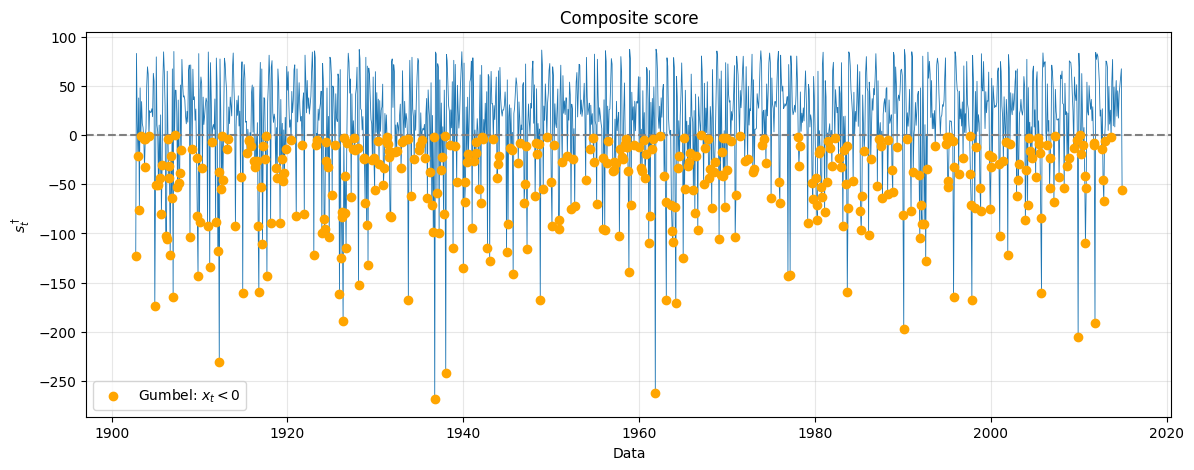

In [174]:
plt.figure(figsize=(14, 5))

plt.plot(series.index, s, linewidth=0.6)

plt.scatter(series.index[mask_gumbel], s[mask_gumbel], color="orange", zorder=3, label=r"Gumbel: $x_t<0$")
# plt.scatter(series.index[mask_lower], s[mask_lower], color="red", s=28, zorder=3, label=r"$\xi_t>0$: $x_t\leq c_t$")
# plt.scatter(series.index[mask_upper], s[mask_upper], color="purple", s=28, zorder=3, label=r"$\xi_t>0$: $x_t>d_t$")

plt.axhline(0, linestyle="--", color='gray')

plt.xlabel("Data")
plt.ylabel(r"$s_t^\dagger$")
plt.title("Composite score")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

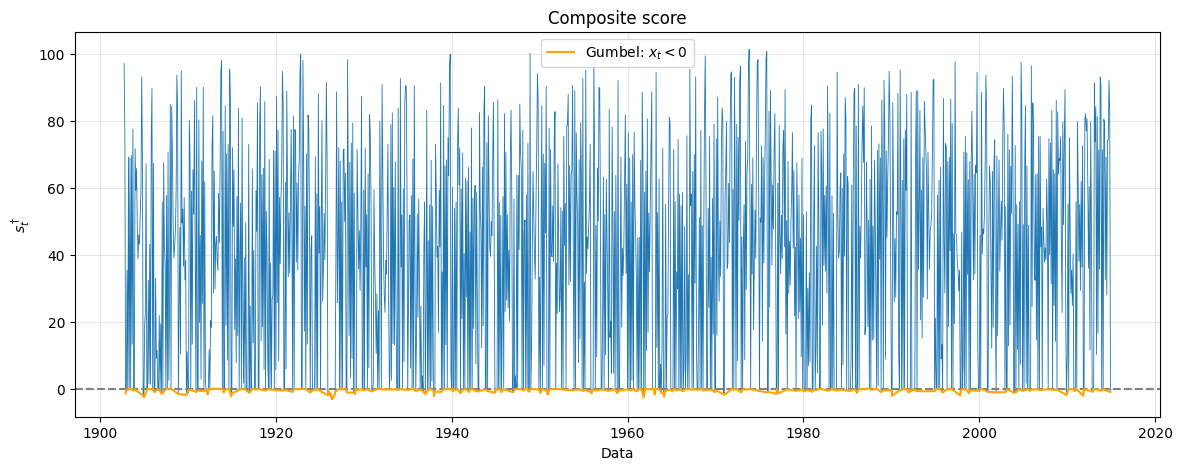

In [134]:
plt.figure(figsize=(14, 5))

plt.plot(series.index, s, linewidth=0.6)

plt.plot(series.index[mask_gumbel], s[mask_gumbel], color="orange", zorder=3, label=r"Gumbel: $x_t<0$")
# plt.scatter(series.index[mask_lower], s[mask_lower], color="red", s=28, zorder=3, label=r"$\xi_t>0$: $x_t\leq c_t$")
# plt.scatter(series.index[mask_upper], s[mask_upper], color="purple", s=28, zorder=3, label=r"$\xi_t>0$: $x_t>d_t$")

plt.axhline(0, linestyle="--", color='gray')

plt.xlabel("Data")
plt.ylabel(r"$s_t^\dagger$")
plt.title("Composite score")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

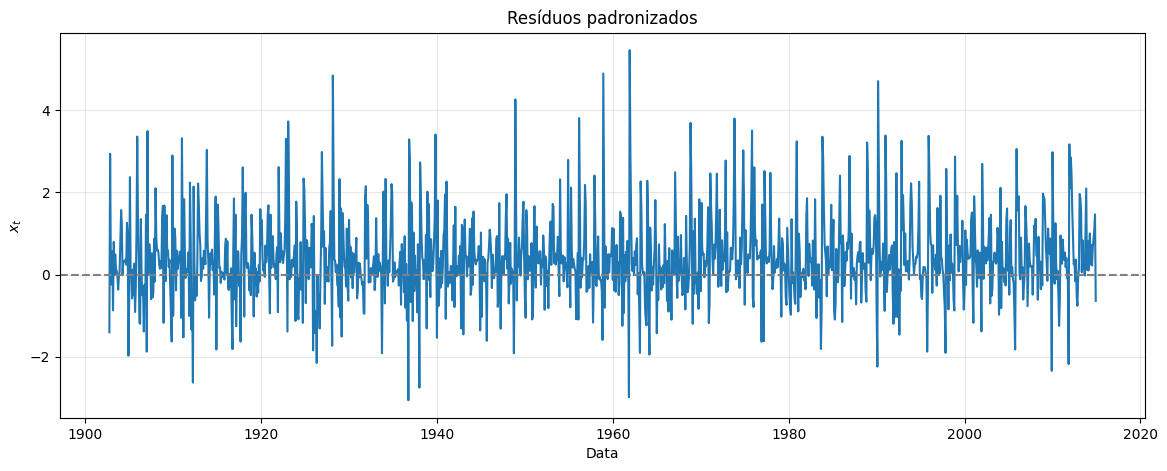

In [175]:
plt.figure(figsize=(14, 5))

plt.plot(series.index, x)
plt.axhline(0, linestyle="--", color='gray')

plt.xlabel("Data")
plt.ylabel(r"$x_t$")
plt.title("Resíduos padronizados")
plt.grid(alpha=0.3)

plt.show()

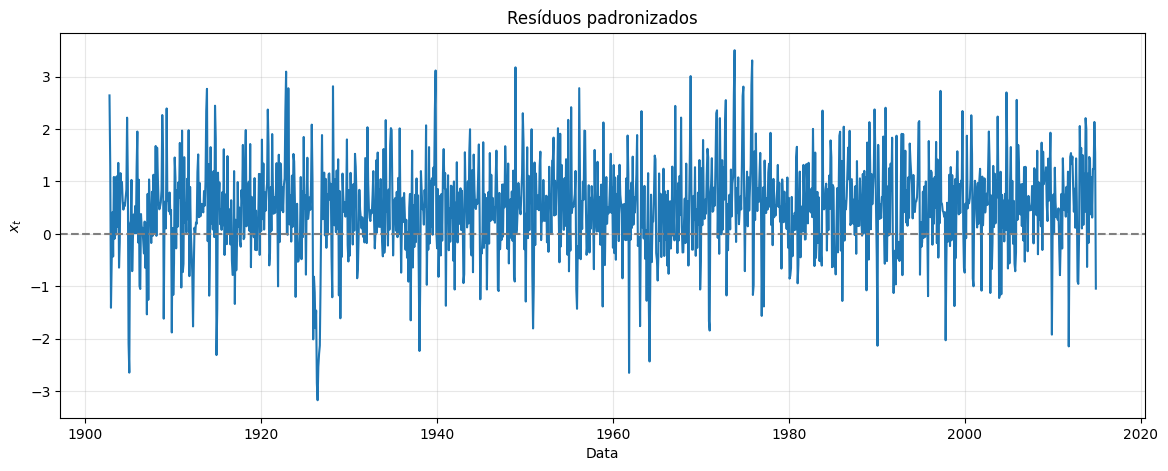

In [96]:
plt.figure(figsize=(14, 5))

plt.plot(series.index, x)
plt.axhline(0, linestyle="--", color='gray')

plt.xlabel("Data")
plt.ylabel(r"$x_t$")
plt.title("Resíduos padronizados")
plt.grid(alpha=0.3)

plt.show()

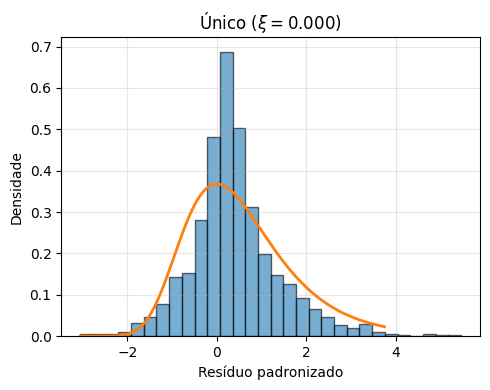

In [176]:
fig, ax = plt.subplots(figsize=(5, 4))

# Grade da densidade teórica
x_grid = np.linspace(np.min(x), np.percentile(x, 99.5), 500)

# Histograma dos resíduos padronizados
ax.hist(x, bins=30, density=True, alpha=0.6, edgecolor="black")
pdf = genextreme.pdf(x_grid, c=-xi_seca_hat, loc=0, scale=1)
ax.plot(x_grid, pdf, linewidth=2) # Densidade teórica

ax.set_title(f"Único ($\\xi={xi_seca_hat:.3f}$)")
ax.set_xlabel("Resíduo padronizado")
ax.set_ylabel("Densidade")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

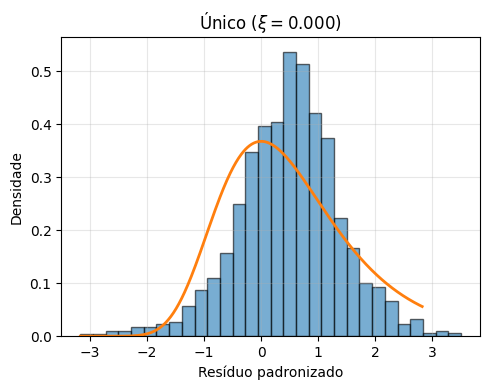

In [101]:
fig, ax = plt.subplots(figsize=(5, 4))

# Grade da densidade teórica
x_grid = np.linspace(np.min(x), np.percentile(x, 99.5), 500)

# Histograma dos resíduos padronizados
ax.hist(x, bins=30, density=True, alpha=0.6, edgecolor="black")
pdf = genextreme.pdf(x_grid, c=-xi_seca_hat, loc=0, scale=1)
ax.plot(x_grid, pdf, linewidth=2) # Densidade teórica

ax.set_title(f"Único ($\\xi={xi_seca_hat:.3f}$)")
ax.set_xlabel("Resíduo padronizado")
ax.set_ylabel("Densidade")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

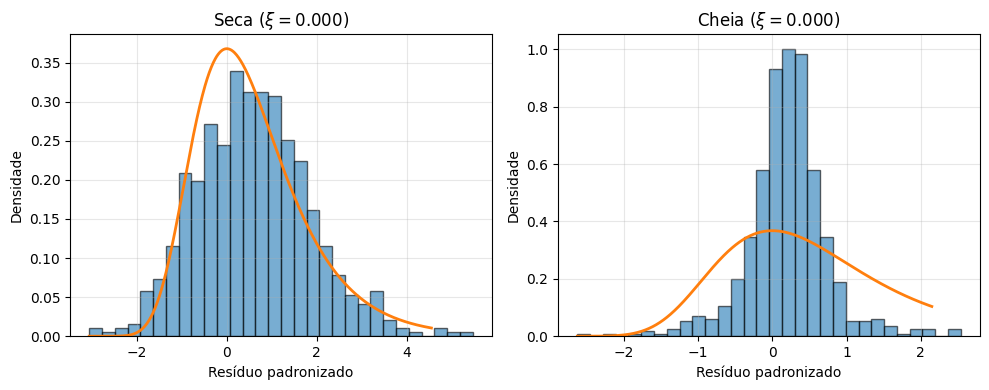

In [177]:
# Separar os resíduos por regime
regimes = [
    (x[dummy == 0], xi_seca_hat, "Seca"),
    (x[dummy == 1], xi_cheia_hat, "Cheia")
]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (x_regime, xi_hat, nome) in zip(axes, regimes):
    # Grade da densidade teórica
    x_grid = np.linspace(np.min(x_regime), np.percentile(x_regime, 99.5), 500)

    # Histograma dos resíduos padronizados
    ax.hist(x_regime, bins=30, density=True, alpha=0.6, edgecolor="black")
    pdf = genextreme.pdf(x_grid, c=-xi_hat, loc=0, scale=1)
    ax.plot(x_grid, pdf, linewidth=2) # Densidade teórica

    ax.set_title(f"{nome} ($\\xi={xi_hat:.3f}$)")
    ax.set_xlabel("Resíduo padronizado")
    ax.set_ylabel("Densidade")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

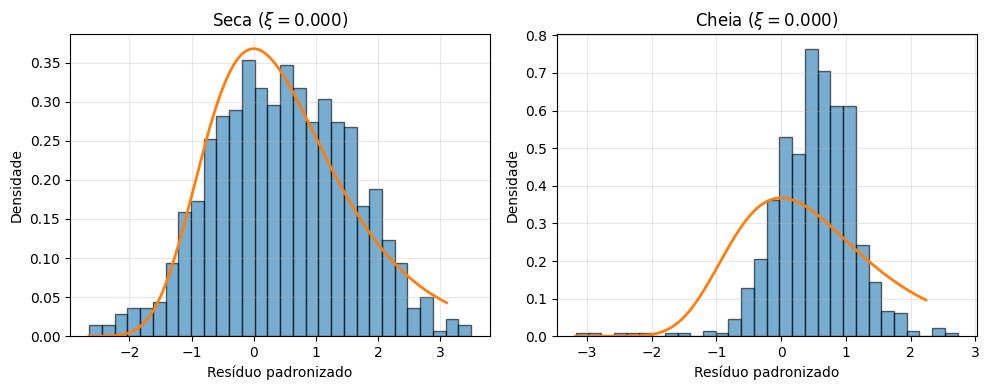

In [97]:
# Separar os resíduos por regime
regimes = [
    (x[dummy == 0], xi_seca_hat, "Seca"),
    (x[dummy == 1], xi_cheia_hat, "Cheia")
]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (x_regime, xi_hat, nome) in zip(axes, regimes):
    # Grade da densidade teórica
    x_grid = np.linspace(np.min(x_regime), np.percentile(x_regime, 99.5), 500)

    # Histograma dos resíduos padronizados
    ax.hist(x_regime, bins=30, density=True, alpha=0.6, edgecolor="black")
    pdf = genextreme.pdf(x_grid, c=-xi_hat, loc=0, scale=1)
    ax.plot(x_grid, pdf, linewidth=2) # Densidade teórica

    ax.set_title(f"{nome} ($\\xi={xi_hat:.3f}$)")
    ax.set_xlabel("Resíduo padronizado")
    ax.set_ylabel("Densidade")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

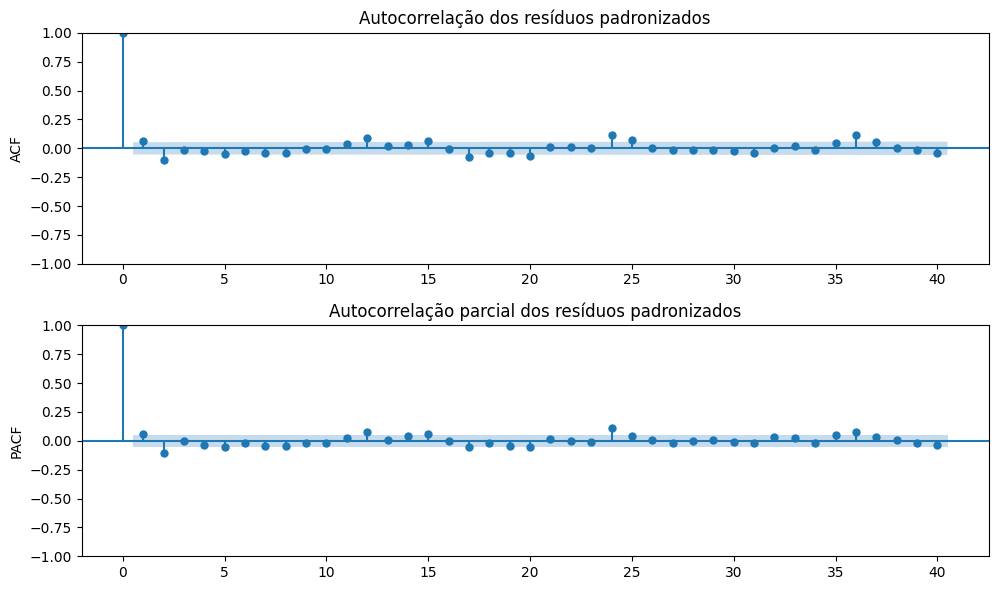

In [182]:
fig, ax = plt.subplots(2, 1, figsize=(10, 6))

plot_acf(x, lags=40, ax=ax[0])
plot_pacf(x, lags=40, ax=ax[1])
ax[0].set_title("Autocorrelação dos resíduos padronizados")
ax[0].set_ylabel("ACF")
ax[1].set_title("Autocorrelação parcial dos resíduos padronizados")
ax[1].set_ylabel("PACF")

plt.tight_layout()
plt.show()

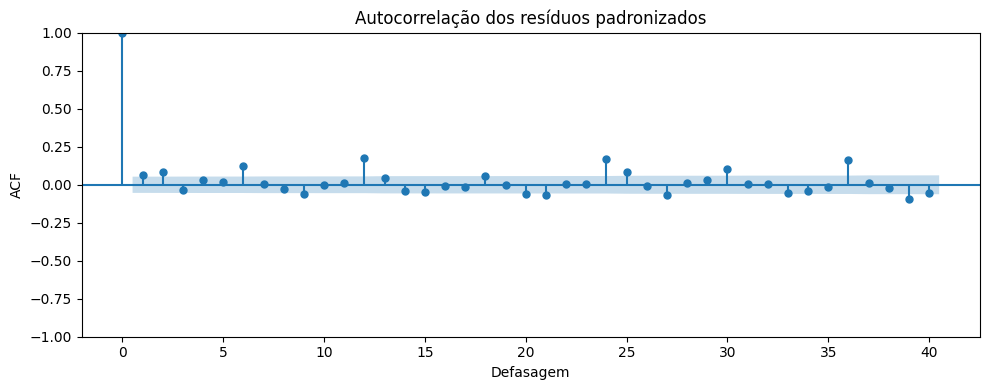

In [98]:
plt.figure(figsize=(10, 4))
plot_acf(x, lags=40, ax=plt.gca())
plt.title("Autocorrelação dos resíduos padronizados")
plt.xlabel("Defasagem")
plt.ylabel("ACF")
plt.tight_layout()
plt.show()

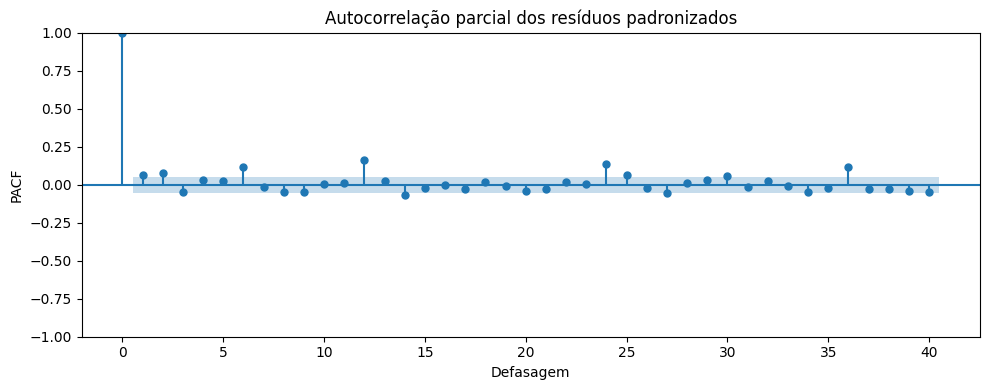

In [99]:
plt.figure(figsize=(10, 4))
plot_pacf(x, lags=40, ax=plt.gca())
plt.title("Autocorrelação parcial dos resíduos padronizados")
plt.xlabel("Defasagem")
plt.ylabel("PACF")
plt.tight_layout()
plt.show()

# Dados Harvey

- Dados Harvey: daily river Exe flow e level na base de Thorverton [https://environment.data.gov.uk/hydrology/station/3c4d4f78-2d0e-474a-b884-65a9daca18fb]  
  Grid Reference: SS9360201602
  River Name: River Exe  
  Catchment Area: 600.9 km²  
  Station Reference (Telemetry): 45118  
  Station ID (WISKI): SS90F011  
  API: https://environment.data.gov.uk/hydrology/doc/reference

In [226]:
path = r"C:\Users\aless\Documents\Mestrado\PUC\Tese\Dados\Thorverton-flow-daily-Qualified.csv"

data = pd.read_csv(path)

data['date'] = pd.to_datetime(data['date'])

data = data.set_index('date').dropna(how='all')
series = data[['value']].resample('ME').max()

print(series.shape)
series.head(3)

(847, 1)


,value
date,
1956-04-30,4.283
1956-05-31,4.214
1956-06-30,11.329


In [31]:
# metadados
pd.set_option('display.max_colwidth', None)
pd.DataFrame(index=['Metadados'], data={
    'Fonte':'''Base de dados de vazão do Rio Amazonas da Agência Nacional de Águas (ANA)''', 
    'Unidade':'centímetros (cm)',
    'Período da série': '{} a {}'.format(series.index.min().strftime('%d/%m/%Y'), series.index.max().strftime('%d/%m/%Y')),
    'Observações': '{} meses'.format(series.shape[0])
}).T

,Metadados
Fonte,Base de dados de vazão do Rio Amazonas da Agência Nacional de Águas (ANA)
Unidade,centímetros (cm)
Período da série,30/04/1956 a 31/10/2026
Observações,847 meses


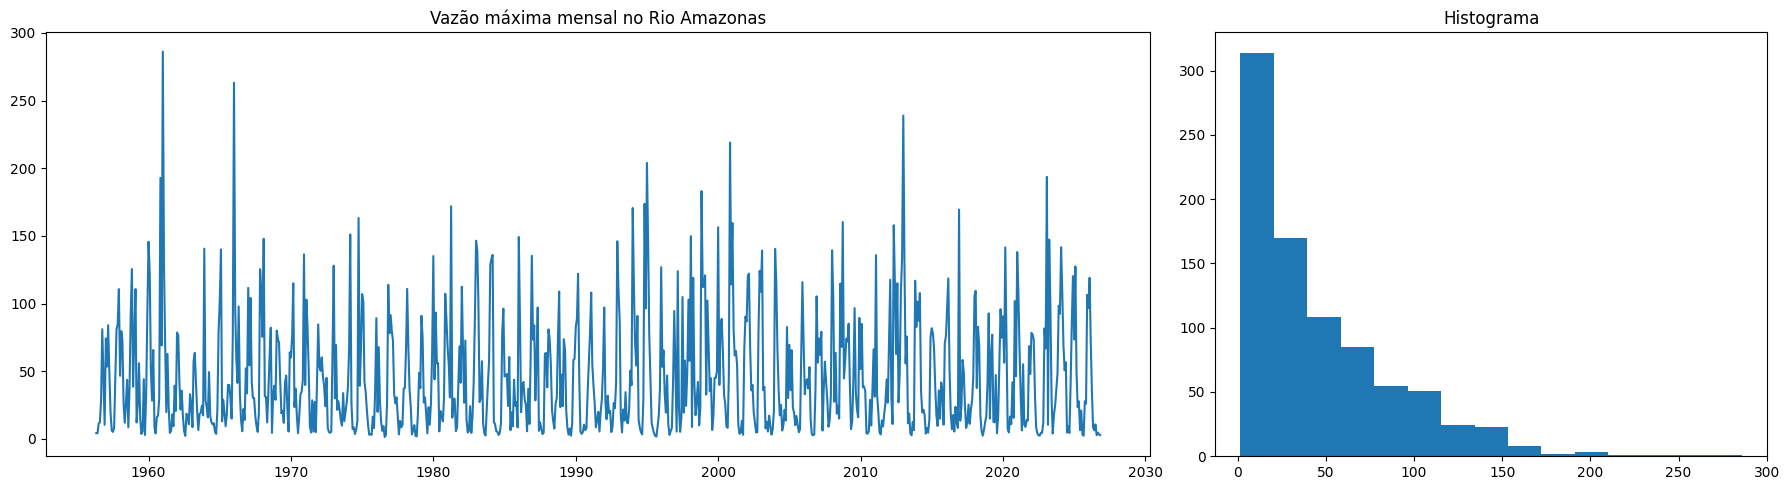

In [32]:
fig, ax = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={'width_ratios': [2, 1]})

ax[0].plot(series)
ax[0].set_title('Vazão máxima mensal no Rio Amazonas')

ax[1].hist(series, bins=15)
ax[1].set_title('Histograma')

plt.tight_layout()
plt.show()

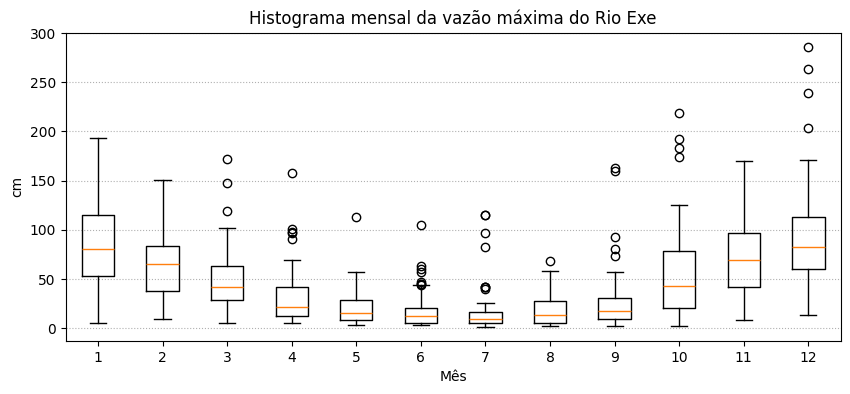

In [38]:
fig, ax = plt.subplots(figsize=(10,4))
plot_data = (series
    .pivot_table(columns=series.index.month, index=series.index.year, values='value')
    .dropna()
)
ax.boxplot(plot_data)
ax.set_ylabel('cm')
ax.set_xlabel('Mês')
ax.grid(axis='y', linestyle=':')
ax.set_title('Histograma mensal da vazão máxima do Rio Exe')
plt.show()

## Modelagem

In [227]:
y = series['value']
mu_init, alpha_init, beta_init = harvey.initial_seasonal_coefficients(y)

t = np.arange(1, len(y) + 1)
gamma_init = harvey.seasonal_component(t, alpha_init, beta_init)
residuos_init = y.to_numpy(dtype=float) - mu_init - gamma_init
varphi_init = np.std(residuos_init)

print(f"mu inicial: {mu_init:.2f}")
print(f"varphi inicial: {varphi_init:.2f}")

mu inicial: 45.89
varphi inicial: 32.93


In [228]:
# temporada de cheia (verão) de abril a setembro
dummy = series.index.month.isin([4,5,6,7,8,9]).astype(int)
bounds = [
    (None, None),   # mu0
    (1e-8, None),   # varphi > 0
    (-0.999, 0.999),  # -1 < phi < 1
    (1e-8, None),  # kappa > 0
    (1e-8, 0.999),     # 0 < xi_seca < 1/2
    (1e-8, 0.999)     # 0 < xi_cheia < 1/2
]
bounds += [(None, None)] * 11  # alpha e beta

init_params = [
    46,     # mu
    33,     # varphi
    0.55,   # phi
    0.3,    # kappa
    0.1,    # xi seca
    0.3, # xi cheia
    *alpha_init,
    *beta_init
]
start = dt.datetime.now()
print(start)
result = harvey.fit(y, dummy, init_params, bounds=bounds, xi_mode="seasonal")
end = dt.datetime.now()
print(f"Tempo de execução: {(end-start).seconds//60:02d}:{(end-start).seconds%60:02d}")

mu_hat, varphi_hat, phi_hat, kappa_hat, xi_seca_hat, xi_cheia_hat = result.params_original[:6]
alpha_hat = result.params_original[6:12]
beta_hat = result.params_original[12:17]

2026-10-23 15:20:52.882637
Tempo de execução: 01:32


In [229]:
print("Convergiu:", result.success)
print("Mensagem:", result.message)

print("\nEstimativas:")
print(f"mu: {result.params_original[0]:.3f}")
print(f"varphi: {result.params_original[1]:.3f}")
print(f"phi: {result.params_original[2]}")
print(f"kappa: {result.params_original[3]}")
print(f"xi seca: {result.params_original[4]}")
print(f"xi cheia: {result.params_original[5]}")

print("\nLog-likelihood =", -result.fun)

Convergiu: True
Mensagem: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH

Estimativas:
mu: 45.545
varphi: 32.985
phi: 0.6580133835121685
kappa: 0.42035391094710606
xi seca: 1e-08
xi cheia: 0.7010473025185313

Log-likelihood = -4130.710619783835


In [188]:
print("Convergiu:", result.success)
print("Mensagem:", result.message)

print("\nEstimativas:")
print(f"mu: {result.params_original[0]:.3f}")
print(f"varphi: {result.params_original[1]:.3f}")
print(f"phi: {result.params_original[2]}")
print(f"kappa: {result.params_original[3]}")
print(f"xi seca: {result.params_original[4]}")
print(f"xi cheia: {result.params_original[5]}")

print("\nLog-likelihood =", -result.fun)

Convergiu: True
Mensagem: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH

Estimativas:
mu: 42.909
varphi: 31.106
phi: 0.14069966840800407
kappa: 0.17374007405721204
xi seca: 1e-08
xi cheia: 0.999

Log-likelihood = -4050.4339993326475


In [189]:
result

         message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
         success: True
          status: 0
             fun: 4050.4339993326475
               x: [ 4.291e+01  3.111e+01 ...  5.434e-01 -9.910e-01]
             nit: 14
             jac: [ 3.406e+00  2.987e+00 ...  2.687e+00  4.287e-01]
            nfev: 342
            njev: 19
        hess_inv: <17x17 LbfgsInvHessProduct with dtype=float64>
 params_original: [ 4.291e+01  3.111e+01 ...  5.434e-01 -9.910e-01]

In [ ]:
salvar_resultados(result, observacoes="Máximos mensais do nível do rio Amazonas")

In [87]:
xi_seca_harvey = 0.6
xi_cheia_harvey = 0
phi_seca_harvey = 8.24
phi_cheia_harvey = 32.13

In [88]:
for xi, phi in [(xi_cheia_harvey, phi_cheia_harvey), (xi_seca_harvey, phi_seca_harvey)]:
    if xi!=0:
        delta = (
            gamma_func(1-xi) - 1
        ) * phi / xi
    else:
        delta = 0.577*phi
    print(delta)

18.53901
16.729391067605587


## Avaliação

In [231]:
mu_filtered, gamma_t, x, s, xi_t = harvey.filter(
    y, mu_hat, varphi_hat, phi_hat, kappa_hat, xi_seca_hat, xi_cheia_hat, dummy, alpha_hat, beta_hat
)
eta_t = mu_filtered + gamma_t
mean_cond = harvey.conditional_mean(mu_filtered, varphi_hat, xi_t, gamma_t)

pit = harvey.cdf(y, mu_filtered, varphi_hat, xi_t, gamma_t)

In [232]:
# regiões modificadas do score
mask_gumbel = (np.abs(xi_t) < 1e-6) & (x < 0)
mask_lower = np.zeros(len(x), dtype=bool)
mask_upper = np.zeros(len(x), dtype=bool)

c, d = {}, {}
c_t = np.full(len(x), np.nan)
d_t = np.full(len(x), np.nan)

for xi_value in np.unique(xi_t):
    if xi_value > 1e-6:
        c[xi_value] = harvey._find_c(xi_value)
        d[xi_value] = harvey._find_d(xi_value)

for i in range(len(x)):
    if xi_t[i] > 1e-6:
        c_t[i], d_t[i] = c[xi_value], d[xi_value]
        mask_lower[i] = x[i] <= c_t[i]
        mask_upper[i] = x[i] > d_t[i]

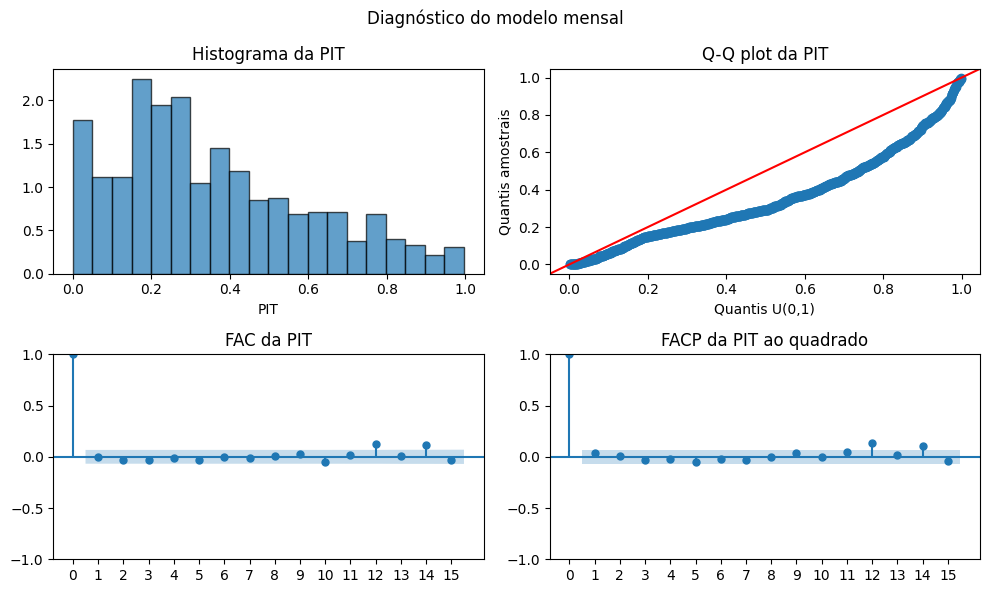

In [233]:
# pit
fig, ax = plt.subplots(2, 2, figsize=(10, 6))

# linha 1
ax[0,0].hist(pit, bins=20, density=True, edgecolor='black', alpha=0.7)
ax[0,0].set_title('Histograma da PIT')
ax[0,0].set_xlabel('PIT')

ax[0,1].set_title('Q-Q plot da PIT')
sm.qqplot(pit, dist=uniform, line='45', ax=ax[0,1], loc=0, scale=1)
ax[0,1].set_xlabel('Quantis U(0,1)')
ax[0,1].set_ylabel('Quantis amostrais')

# linha 2
lags = 15

plot_acf(pit, lags=lags, ax=ax[1,0], title='FAC da PIT')
ax[1,0].set_xticks(np.arange(lags+1))
ax[1,0].set_xticklabels(np.arange(lags+1))

plot_pacf(pit**2, lags=lags, ax=ax[1,1], title='FACP da PIT ao quadrado')
ax[1,1].set_xticks(np.arange(lags+1))
ax[1,1].set_xticklabels(np.arange(lags+1))

fig.suptitle('Diagnóstico do modelo mensal')
fig.tight_layout()
plt.show()

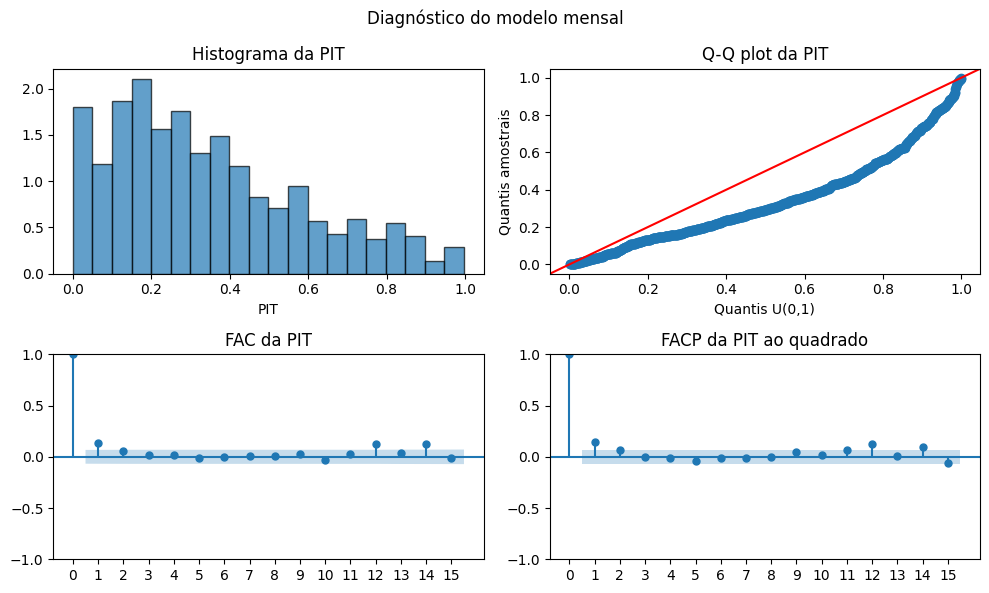

In [146]:
# pit
fig, ax = plt.subplots(2, 2, figsize=(10, 6))

# linha 1
ax[0,0].hist(pit, bins=20, density=True, edgecolor='black', alpha=0.7)
ax[0,0].set_title('Histograma da PIT')
ax[0,0].set_xlabel('PIT')

ax[0,1].set_title('Q-Q plot da PIT')
sm.qqplot(pit, dist=uniform, line='45', ax=ax[0,1], loc=0, scale=1)
ax[0,1].set_xlabel('Quantis U(0,1)')
ax[0,1].set_ylabel('Quantis amostrais')

# linha 2
lags = 15

plot_acf(pit, lags=lags, ax=ax[1,0], title='FAC da PIT')
ax[1,0].set_xticks(np.arange(lags+1))
ax[1,0].set_xticklabels(np.arange(lags+1))

plot_pacf(pit**2, lags=lags, ax=ax[1,1], title='FACP da PIT ao quadrado')
ax[1,1].set_xticks(np.arange(lags+1))
ax[1,1].set_xticklabels(np.arange(lags+1))

fig.suptitle('Diagnóstico do modelo mensal')
fig.tight_layout()
plt.show()

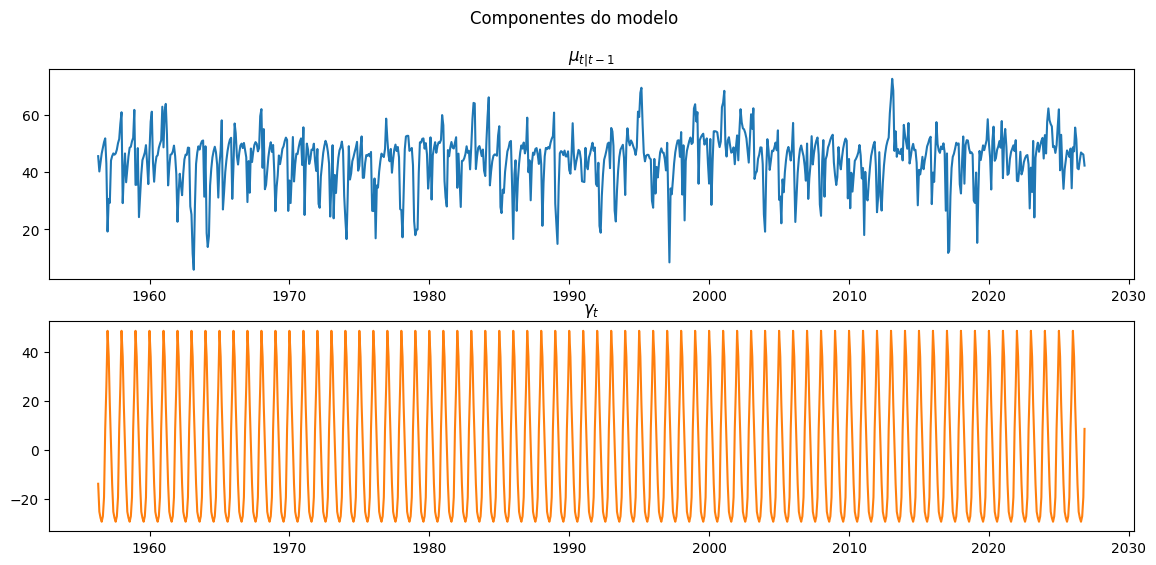

In [234]:
fig, ax = plt.subplots(2, 1, figsize=(14, 6))

ax[0].plot(series.index, mu_filtered, label=r"$\mu_{t|t-1}$")
ax[0].set_title(r"$\mu_{t|t-1}$")

ax[1].plot(series.index, gamma_t, label=r"$\gamma_t$", color='C1')
ax[1].set_title(r"$\gamma_t$")

fig.suptitle("Componentes do modelo")
# plt.legend()
plt.show()

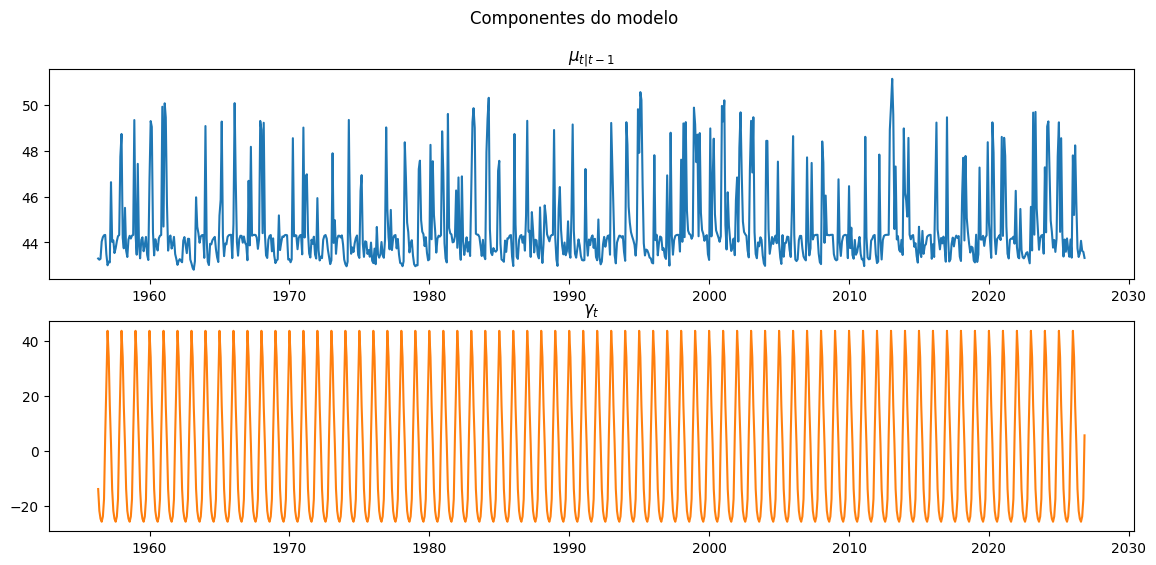

In [147]:
fig, ax = plt.subplots(2, 1, figsize=(14, 6))

ax[0].plot(series.index, mu_filtered, label=r"$\mu_{t|t-1}$")
ax[0].set_title(r"$\mu_{t|t-1}$")

ax[1].plot(series.index, gamma_t, label=r"$\gamma_t$", color='C1')
ax[1].set_title(r"$\gamma_t$")

fig.suptitle("Componentes do modelo")
# plt.legend()
plt.show()

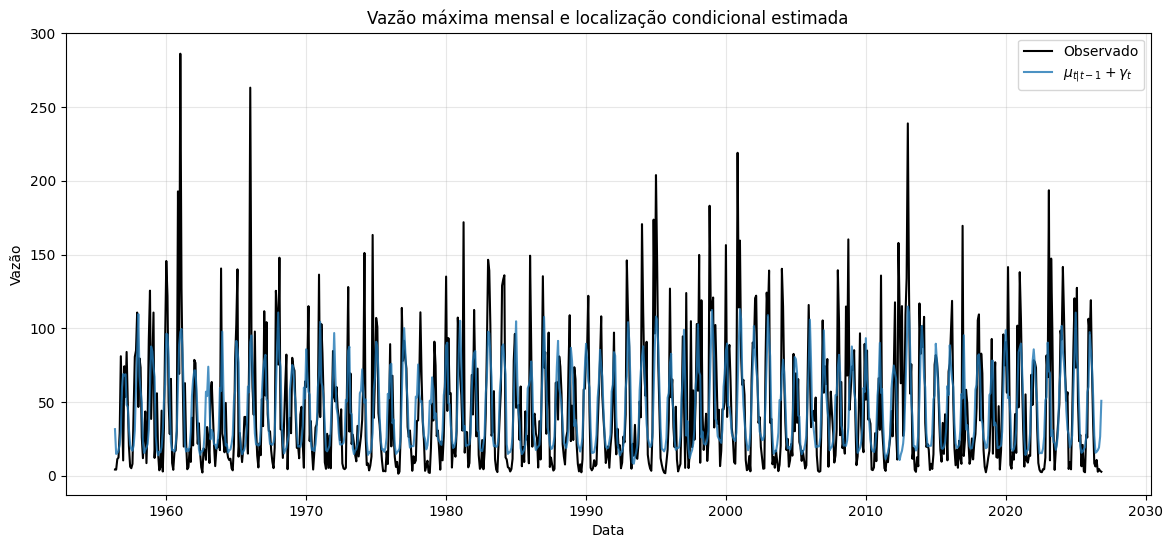

In [235]:
plt.figure(figsize=(14, 6))

plt.plot(series.index, series, label="Observado", color='black')
plt.plot(series.index, eta_t, label=r"$\mu_{t|t-1} + \gamma_t$", alpha=0.8)
# plt.plot(series.index, mean_cond, label=r"$E[y_t|\mathcal{F}_{t-1}]$")

plt.xlabel("Data")
plt.ylabel("Vazão")
plt.title("Vazão máxima mensal e localização condicional estimada")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

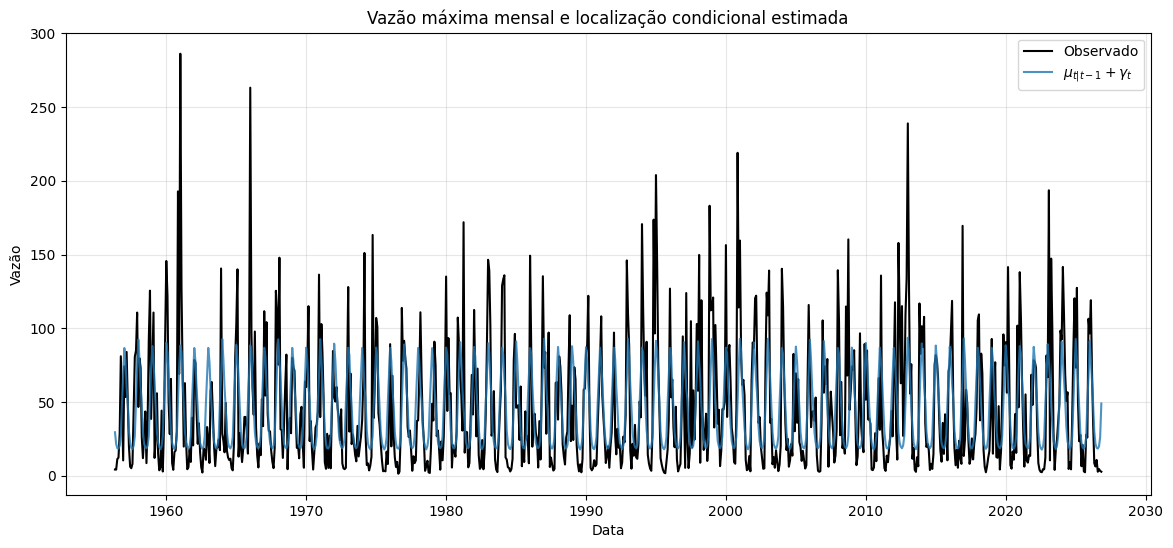

In [148]:
plt.figure(figsize=(14, 6))

plt.plot(series.index, series, label="Observado", color='black')
plt.plot(series.index, eta_t, label=r"$\mu_{t|t-1} + \gamma_t$", alpha=0.8)
# plt.plot(series.index, mean_cond, label=r"$E[y_t|\mathcal{F}_{t-1}]$")

plt.xlabel("Data")
plt.ylabel("Vazão")
plt.title("Vazão máxima mensal e localização condicional estimada")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

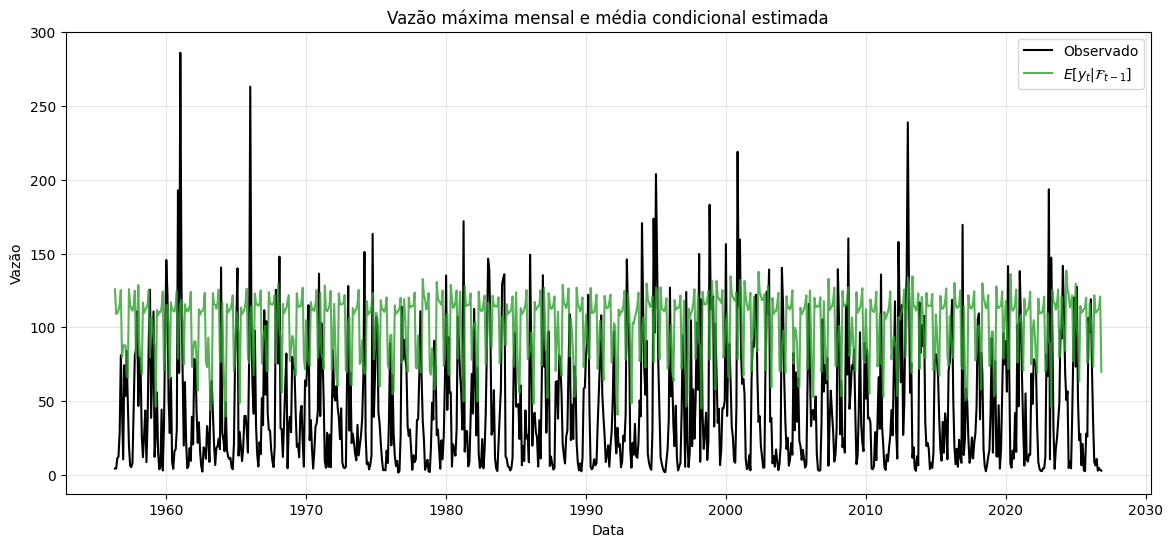

In [236]:
plt.figure(figsize=(14, 6))

plt.plot(series.index, series, label="Observado", color='black')
# plt.plot(series.index, eta_t, label=r"$\mu_{t|t-1} + \gamma_t$")
plt.plot(series.index, mean_cond, label=r"$E[y_t|\mathcal{F}_{t-1}]$", color='C2', alpha=0.8)

plt.xlabel("Data")
plt.ylabel("Vazão")
plt.title("Vazão máxima mensal e média condicional estimada")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

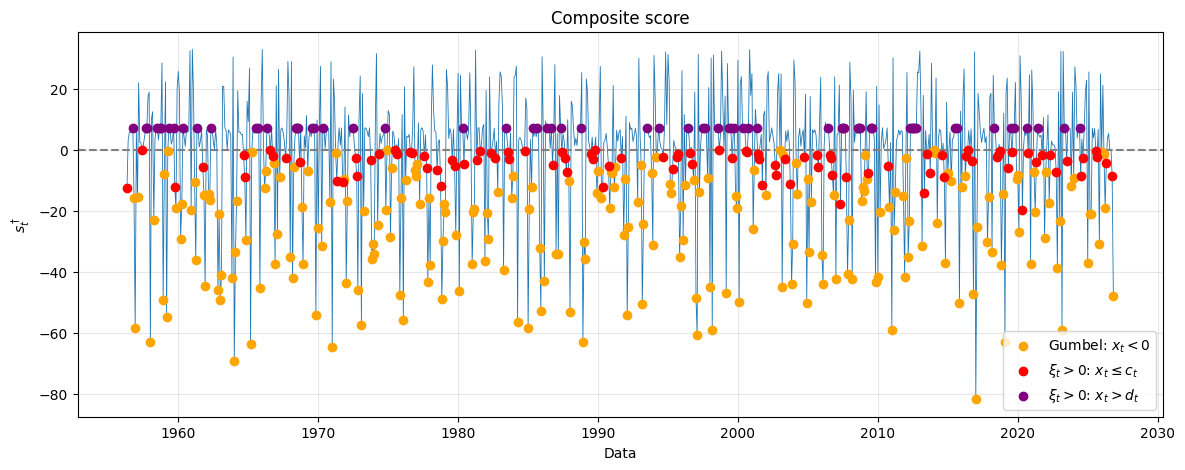

In [237]:
plt.figure(figsize=(14, 5))

plt.plot(series.index, s, linewidth=0.6)

plt.scatter(series.index[mask_gumbel], s[mask_gumbel], color="orange", zorder=3, label=r"Gumbel: $x_t<0$")
plt.scatter(series.index[mask_lower], s[mask_lower], color="red", zorder=3, label=r"$\xi_t>0$: $x_t\leq c_t$")
plt.scatter(series.index[mask_upper], s[mask_upper], color="purple", zorder=3, label=r"$\xi_t>0$: $x_t>d_t$")

plt.axhline(0, linestyle="--", color='gray')

plt.xlabel("Data")
plt.ylabel(r"$s_t^\dagger$")
plt.title("Composite score")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [239]:
c = harvey._find_c(xi_cheia_hat)
d = harvey._find_d(xi_cheia_hat)
I = harvey.fisher_information(xi_cheia_hat, varphi_hat)
print(f'c = {c:.3f} \nd = {d:.3f} \nI = {I:.3f}')

s_c = harvey.score(varphi_hat*c, xi_cheia_hat, 0, 0, varphi_hat)/ I
s_d = harvey.score(varphi_hat*d, xi_cheia_hat, 0, 0, varphi_hat) / I
print(f'\ns(c) = {s_c:.3f} \ns(d) = {s_d:.3f}')

ds_c = harvey.score_derivative(c, xi_cheia_hat)
ds_d = harvey.score_derivative(d, xi_cheia_hat)
print(f"\ns\'(c) = {ds_c:.3f} \ns\'(d) = {ds_d:.3f}")

c = -0.445 
d = 0.403 
I = 0.003

s(c) = -0.034 
s(d) = 7.145

s'(c) = 1.000 
s'(d) = -0.000


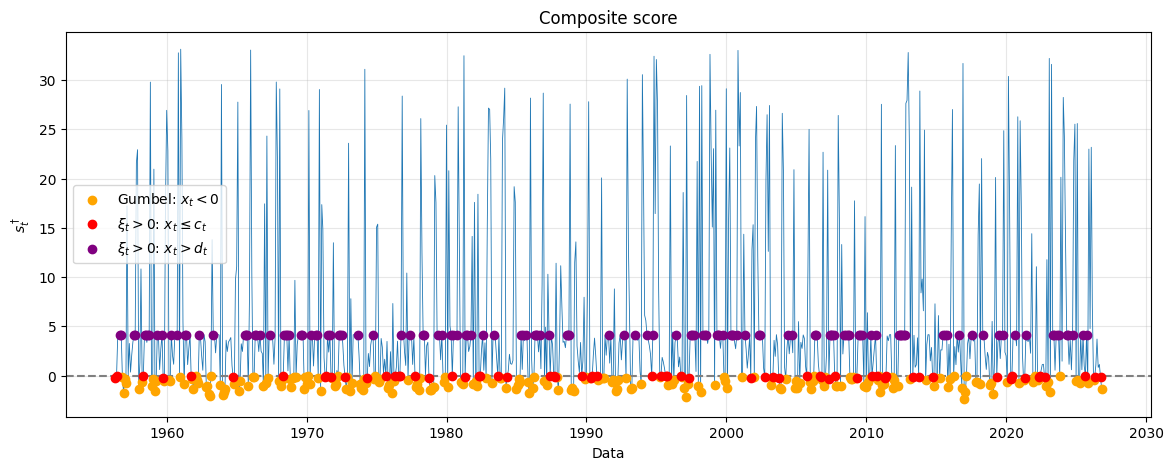

In [158]:
plt.figure(figsize=(14, 5))

plt.plot(series.index, s, linewidth=0.6)

plt.scatter(series.index[mask_gumbel], s[mask_gumbel], color="orange", zorder=3, label=r"Gumbel: $x_t<0$")
plt.scatter(series.index[mask_lower], s[mask_lower], color="red", zorder=3, label=r"$\xi_t>0$: $x_t\leq c_t$")
plt.scatter(series.index[mask_upper], s[mask_upper], color="purple", zorder=3, label=r"$\xi_t>0$: $x_t>d_t$")

plt.axhline(0, linestyle="--", color='gray')

plt.xlabel("Data")
plt.ylabel(r"$s_t^\dagger$")
plt.title("Composite score")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

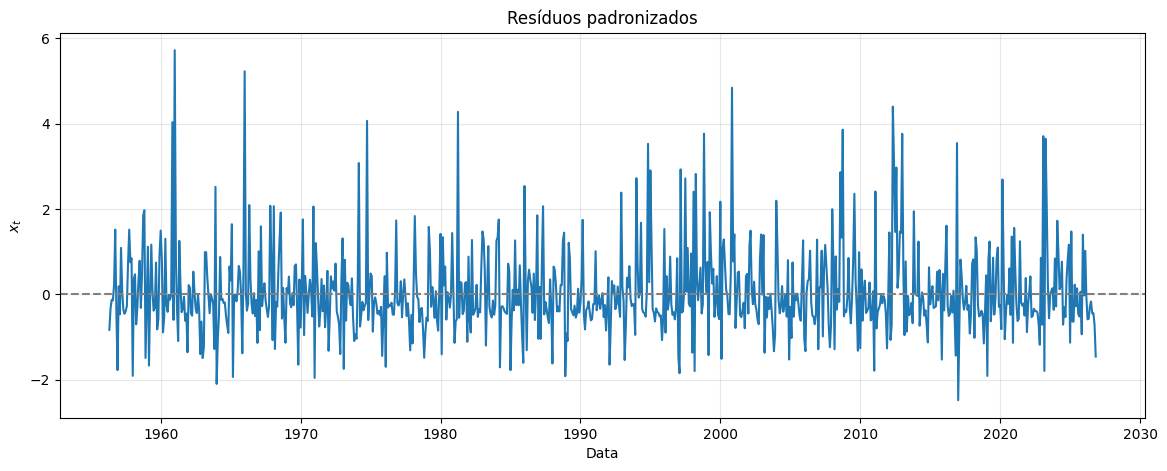

In [241]:
plt.figure(figsize=(14, 5))

plt.plot(series.index, x)
plt.axhline(0, linestyle="--", color='gray')

plt.xlabel("Data")
plt.ylabel(r"$x_t$")
plt.title("Resíduos padronizados")
plt.grid(alpha=0.3)

plt.show()

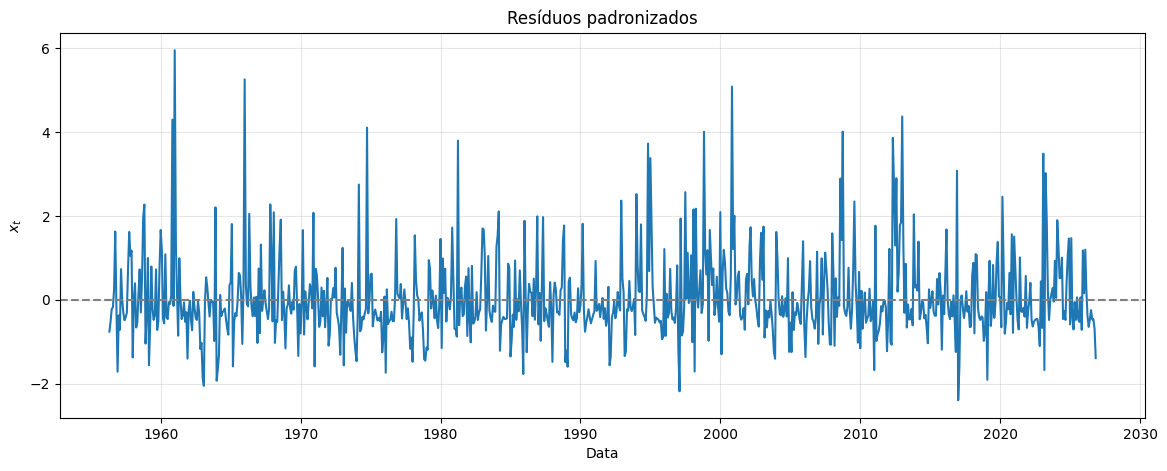

In [154]:
plt.figure(figsize=(14, 5))

plt.plot(series.index, x)
plt.axhline(0, linestyle="--", color='gray')

plt.xlabel("Data")
plt.ylabel(r"$x_t$")
plt.title("Resíduos padronizados")
plt.grid(alpha=0.3)

plt.show()

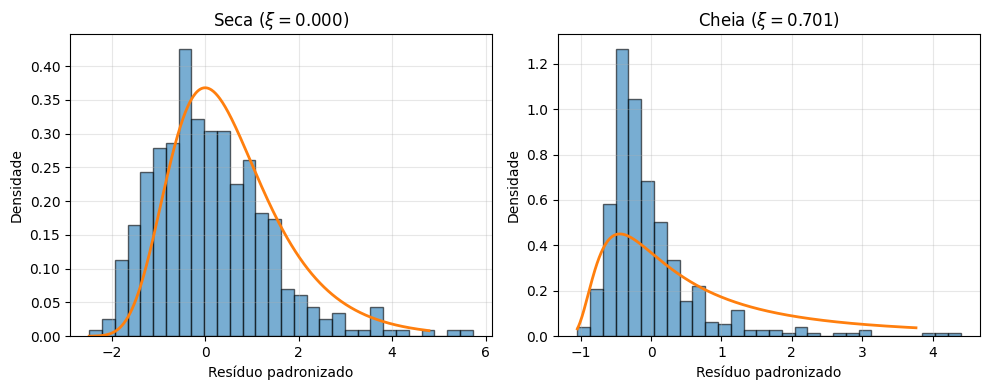

In [242]:
# Separar os resíduos por regime
regimes = [
    (x[dummy == 0], xi_seca_hat, "Seca"),
    (x[dummy == 1], xi_cheia_hat, "Cheia")
]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (x_regime, xi_hat, nome) in zip(axes, regimes):
    # Grade da densidade teórica
    x_grid = np.linspace(np.min(x_regime), np.percentile(x_regime, 99.5), 500)

    # Histograma dos resíduos padronizados
    ax.hist(x_regime, bins=30, density=True, alpha=0.6, edgecolor="black")
    pdf = genextreme.pdf(x_grid, c=-xi_hat, loc=0, scale=1)
    ax.plot(x_grid, pdf, linewidth=2) # Densidade teórica

    ax.set_title(f"{nome} ($\\xi={xi_hat:.3f}$)")
    ax.set_xlabel("Resíduo padronizado")
    ax.set_ylabel("Densidade")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

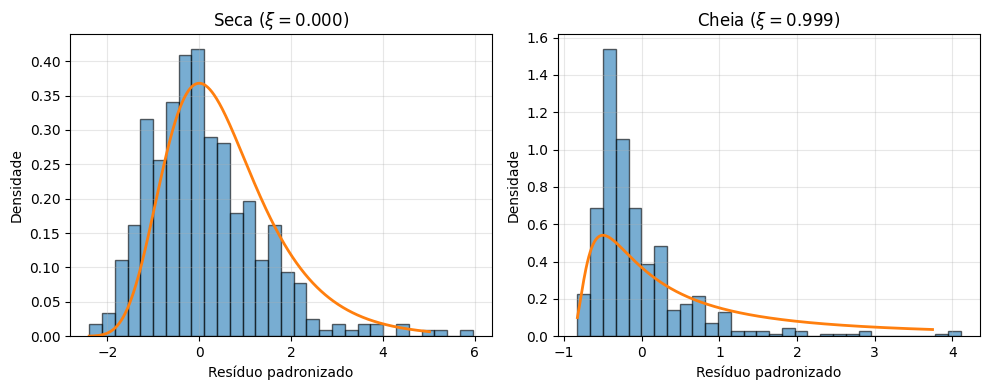

In [155]:
# Separar os resíduos por regime
regimes = [
    (x[dummy == 0], xi_seca_hat, "Seca"),
    (x[dummy == 1], xi_cheia_hat, "Cheia")
]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (x_regime, xi_hat, nome) in zip(axes, regimes):
    # Grade da densidade teórica
    x_grid = np.linspace(np.min(x_regime), np.percentile(x_regime, 99.5), 500)

    # Histograma dos resíduos padronizados
    ax.hist(x_regime, bins=30, density=True, alpha=0.6, edgecolor="black")
    pdf = genextreme.pdf(x_grid, c=-xi_hat, loc=0, scale=1)
    ax.plot(x_grid, pdf, linewidth=2) # Densidade teórica

    ax.set_title(f"{nome} ($\\xi={xi_hat:.3f}$)")
    ax.set_xlabel("Resíduo padronizado")
    ax.set_ylabel("Densidade")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

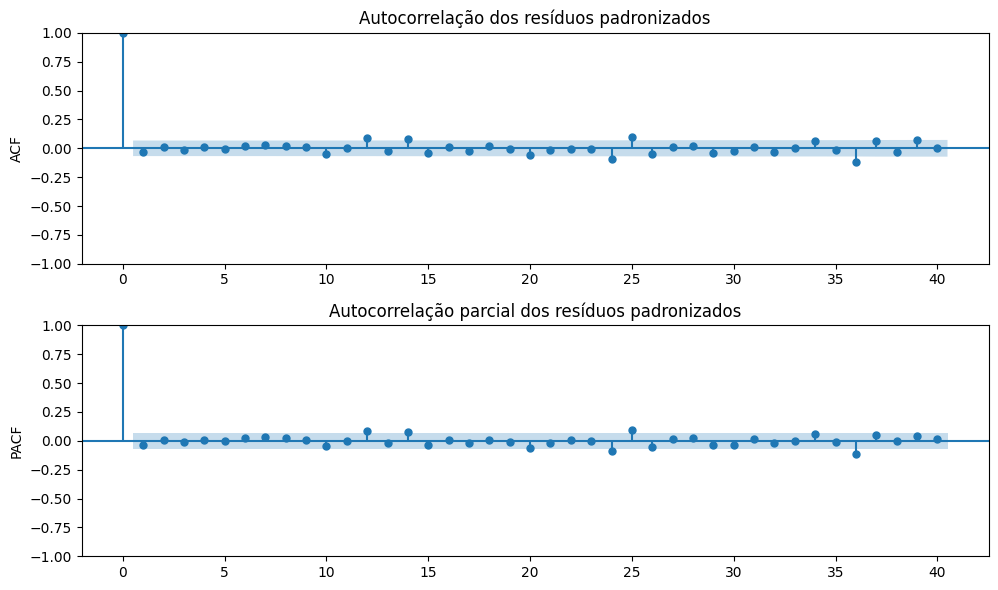

In [243]:
fig, ax = plt.subplots(2, 1, figsize=(10, 6))

plot_acf(x, lags=40, ax=ax[0])
plot_pacf(x, lags=40, ax=ax[1])
ax[0].set_title("Autocorrelação dos resíduos padronizados")
ax[0].set_ylabel("ACF")
ax[1].set_title("Autocorrelação parcial dos resíduos padronizados")
ax[1].set_ylabel("PACF")

plt.tight_layout()
plt.show()

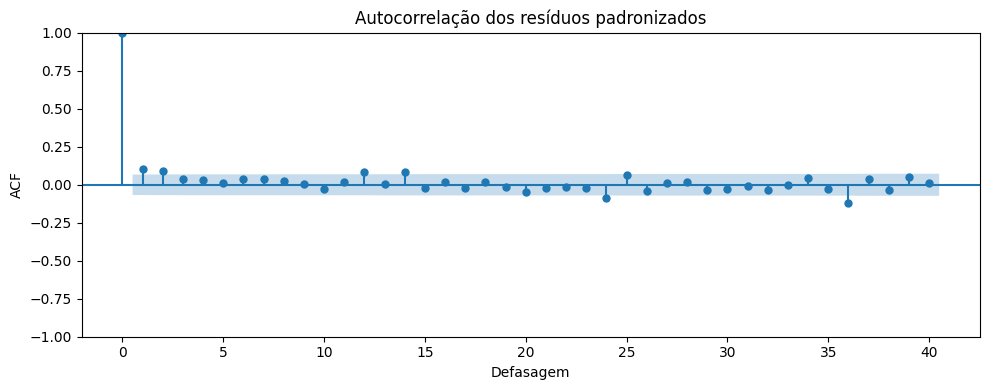

In [156]:
plt.figure(figsize=(10, 4))
plot_acf(x, lags=40, ax=plt.gca())
plt.title("Autocorrelação dos resíduos padronizados")
plt.xlabel("Defasagem")
plt.ylabel("ACF")
plt.tight_layout()
plt.show()

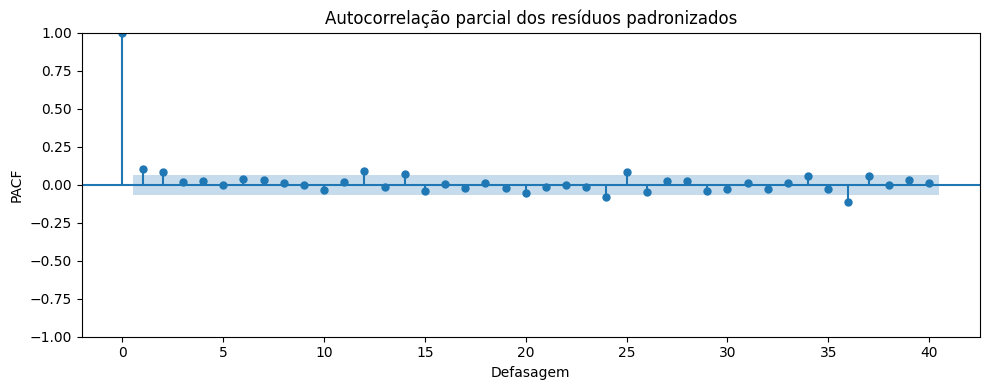

In [157]:
plt.figure(figsize=(10, 4))
plot_pacf(x, lags=40, ax=plt.gca())
plt.title("Autocorrelação parcial dos resíduos padronizados")
plt.xlabel("Defasagem")
plt.ylabel("PACF")
plt.tight_layout()
plt.show()